## Dataset Description

This dataset include data for the estimation of obesity levels in individuals from the countries of Mexico, Peru and Colombia, based on their eating habits and physical condition. The data contains 17 attributes and 2111 records, the records are labeled with the class variable NObesity (Obesity Level), that allows classification of the data using the values of Insufficient Weight, Normal Weight, Overweight Level I, Overweight Level II, Obesity Type I, Obesity Type II and Obesity Type III. 77% of the data was generated synthetically using the Weka tool and the SMOTE filter, 23% of the data was collected directly from users through a web platform

### 📊 Dataset Features

| Column Name                    | Description                                      | Type          |
|-------------------------------|--------------------------------------------------|---------------|
| `Gender`                      | Gender of the individual                         | Categorical   |
| `Age`                         | Age in years                                     | Float     |
| `Height`                      | Height in meters                                 | Float     |
| `Weight`                      | Weight in kilograms                              | Float     |
| `family_history_with_overweight` | Whether the person has family history of overweight | Binary   |
| `FAVC`                        | Frequent consumption of high-calorie food        | Binary   |
| `FCVC`                        | Frequency of vegetable consumption               | Numerical     |
| `NCP`                         | Number of main meals per day                     | Float     |
| `CAEC`                        | Consumption of food between meals                | Categorical (Ordinal) |
| `SMOKE`                       | Smoking habit                                    | Binary   |
| `CH2O`                        | Daily water consumption                          | Float     |
| `SCC`                         | Whether they monitor calorie consumption         | Binary   |
| `FAF`                         | Physical activity frequency                      | Float     |
| `TUE`                         | Time spent using technology devices              | Integer     |
| `CALC`                        | Frequency of alcohol consumption                 | Categorical (Ordinal) |
| `MTRANS`                      | Transportation method used                       | Categorical   |
| `NObeyesdad`                  | **Target variable**: Obesity level (7 categories) | Categorical (Multi-class) |


## Import Libraries

In [152]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import VotingClassifier
from sklearn.svm import LinearSVC
from sklearn.feature_selection import SelectFromModel
from lightgbm import early_stopping, log_evaluation
import warnings
warnings.filterwarnings('ignore')


## Download Data

In [3]:
data = pd.read_csv('Estimation of obesity levels/ObesityDataSet_raw_and_data_sinthetic.csv')

# Data Mining Section 

## Exploring the Dataset

In [4]:
data.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [6]:
data.shape

(2111, 17)

In [7]:
data.isna().sum()

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

In [8]:
data.rename(columns={
    'Gender': 'gender',
    'Age': 'age',
    'Height': 'height',
    'Weight': 'weight',
    'family_history_with_overweight': 'family_history_overweight',
    'FAVC': 'high_caloric_food',
    'FCVC': 'veggies_freq',
    'NCP': 'meal_count',
    'CAEC': 'snacking', # Do you eat any food between meals?	
    'SMOKE': 'smokes',
    'CH2O': 'water_intake',
    'SCC': 'calorie_monitoring',
    'FAF': 'exercise_freq',
    'TUE': 'screen_time',
    'CALC': 'alcohol_intake',
    'MTRANS': 'transport_type',
    'NObeyesdad': 'obesity_level'
}, inplace=True)


In [9]:
data.head(20)

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,obesity_level
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II
5,Male,29.0,1.62,53.0,no,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Automobile,Normal_Weight
6,Female,23.0,1.50,55.0,yes,yes,3.0,3.0,Sometimes,no,2.0,no,1.0,0.0,Sometimes,Motorbike,Normal_Weight
7,Male,22.0,1.64,53.0,no,no,2.0,3.0,Sometimes,no,2.0,no,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
8,Male,24.0,1.78,64.0,yes,yes,3.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Frequently,Public_Transportation,Normal_Weight
9,Male,22.0,1.72,68.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight


In [10]:
def get_types(dataset):
    numeric = dataset.select_dtypes(include=[int, float]).columns.tolist()
    categorical = dataset.select_dtypes(include=[object]).columns.tolist()
    return numeric, categorical

In [11]:
numerical_df, categorical_df = get_types(data)
numeric= data[numerical_df]
categorical = data[categorical_df]

In [12]:
numeric.describe()

,age,height,weight,veggies_freq,meal_count,water_intake,exercise_freq,screen_time
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [13]:
numeric= data[numerical_df]
categorical = data[categorical_df]

In [14]:
for col in numeric:
    print(f"\nValue distribution in column: {col}")
    print(data[col].value_counts(normalize=True))



Value distribution in column: age
age
18.000000    0.060635
26.000000    0.047845
21.000000    0.045476
23.000000    0.042160
19.000000    0.027949
               ...   
23.320120    0.000474
34.243146    0.000474
18.549437    0.000474
36.310292    0.000474
23.664709    0.000474
Name: proportion, Length: 1402, dtype: float64

Value distribution in column: height
height
1.700000    0.028423
1.650000    0.023685
1.600000    0.020369
1.750000    0.018475
1.620000    0.017054
              ...   
1.842943    0.000474
1.706082    0.000474
1.704141    0.000474
1.705813    0.000474
1.738836    0.000474
Name: proportion, Length: 1574, dtype: float64

Value distribution in column: weight
weight
80.000000     0.027949
70.000000     0.020369
50.000000     0.019896
75.000000     0.018948
60.000000     0.017527
                ...   
65.140408     0.000474
87.279890     0.000474
67.083121     0.000474
90.138680     0.000474
133.472641    0.000474
Name: proportion, Length: 1525, dtype: float64

Val

In [15]:
categorical.describe()

,gender,family_history_overweight,high_caloric_food,snacking,smokes,calorie_monitoring,alcohol_intake,transport_type,obesity_level
count,2111,2111,2111,2111,2111,2111,2111,2111,2111
unique,2,2,2,4,2,2,4,5,7
top,Male,yes,yes,Sometimes,no,no,Sometimes,Public_Transportation,Obesity_Type_I
freq,1068,1726,1866,1765,2067,2015,1401,1580,351


In [16]:
for col in categorical:
    print(f"\n Value distribution in column: {col}")
    print(data[col].value_counts(normalize=True))


 Value distribution in column: gender
gender
Male      0.505921
Female    0.494079
Name: proportion, dtype: float64

 Value distribution in column: family_history_overweight
family_history_overweight
yes    0.817622
no     0.182378
Name: proportion, dtype: float64

 Value distribution in column: high_caloric_food
high_caloric_food
yes    0.883941
no     0.116059
Name: proportion, dtype: float64

 Value distribution in column: snacking
snacking
Sometimes     0.836097
Frequently    0.114638
Always        0.025107
no            0.024159
Name: proportion, dtype: float64

 Value distribution in column: smokes
smokes
no     0.979157
yes    0.020843
Name: proportion, dtype: float64

 Value distribution in column: calorie_monitoring
calorie_monitoring
no     0.954524
yes    0.045476
Name: proportion, dtype: float64

 Value distribution in column: alcohol_intake
alcohol_intake
Sometimes     0.663667
no            0.302700
Frequently    0.033160
Always        0.000474
Name: proportion, dtype: f

In [17]:
print("Proportion of each class:")
print(data['obesity_level'].value_counts(normalize=True).round(3))


Proportion of each class:
obesity_level
Obesity_Type_I         0.166
Obesity_Type_III       0.153
Obesity_Type_II        0.141
Overweight_Level_I     0.137
Overweight_Level_II    0.137
Normal_Weight          0.136
Insufficient_Weight    0.129
Name: proportion, dtype: float64


## Categorical Analysis

### Transport Type VS Obesity Level

In [18]:
crosstab = pd.crosstab(data['obesity_level'], data['transport_type'])
crosstab

transport_type,Automobile,Bike,Motorbike,Public_Transportation,Walking
obesity_level,,,,,
Insufficient_Weight,46,0,0,220,6
Normal_Weight,45,4,6,200,32
Obesity_Type_I,110,0,3,236,2
Obesity_Type_II,95,1,0,200,1
Obesity_Type_III,1,0,0,323,0
Overweight_Level_I,66,2,1,212,9
Overweight_Level_II,94,0,1,189,6


<div dir="rtl">
تقريباً جميع الفئات تعتمد بشكل كبير على وسائل النقل العامة
في فئة "Obesity_Type_III" ظهر أن 323 شخصاً من أصل 324 يستخدمون النقل العام (أي نحو 99.7%)

في بقية الفئات تتراوح النسبة بين حوالي 65% إلى 80% باستخدام النقل العام
هذا يشير إلى أن النقل العام هو الخيار الأساسي لمعظم الأفراد بغض النظر عن مستوى السمنة


</div>

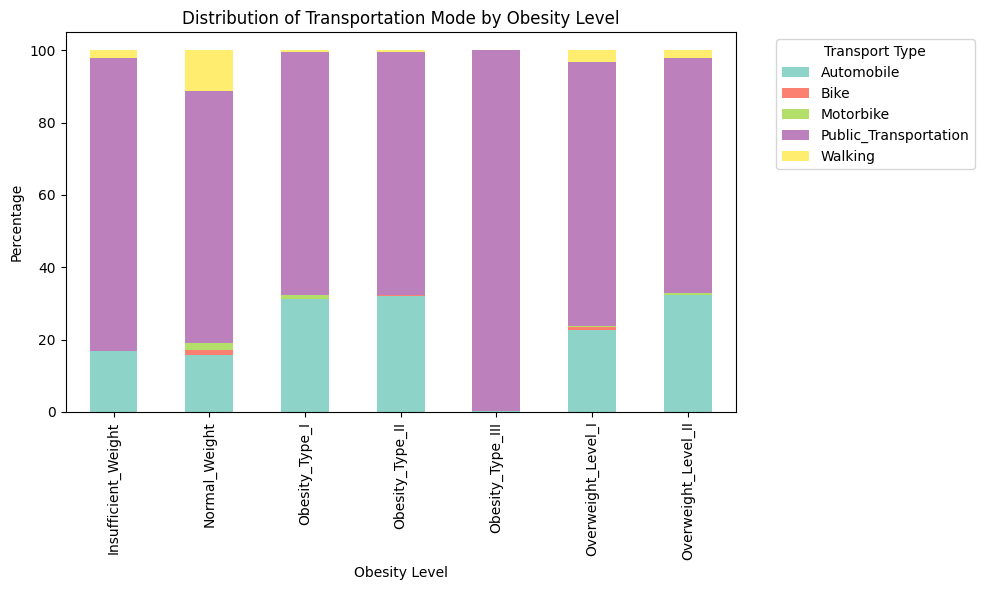

In [19]:
crosstab_percent = crosstab.div(crosstab.sum(axis=1), axis=0) * 100

crosstab_percent.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Set3')
plt.title("Distribution of Transportation Mode by Obesity Level")
plt.ylabel("Percentage")
plt.xlabel("Obesity Level")
plt.legend(title="Transport Type", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

<div dir='rtl'>
لنجر اختبر كاي تربيع

In [20]:
from scipy.stats import chi2_contingency

table = pd.crosstab(data['obesity_level'], data['transport_type'])
chi2, p, dof, expected = chi2_contingency(table)
print(f"P-value: {p}")


P-value: 5.1779152038359274e-48


<div dir='rtl'>
يوجد ارتباط إحصائي قوي بين obesity_level و transport_type

<Axes: xlabel='transport_type', ylabel='obesity_level'>

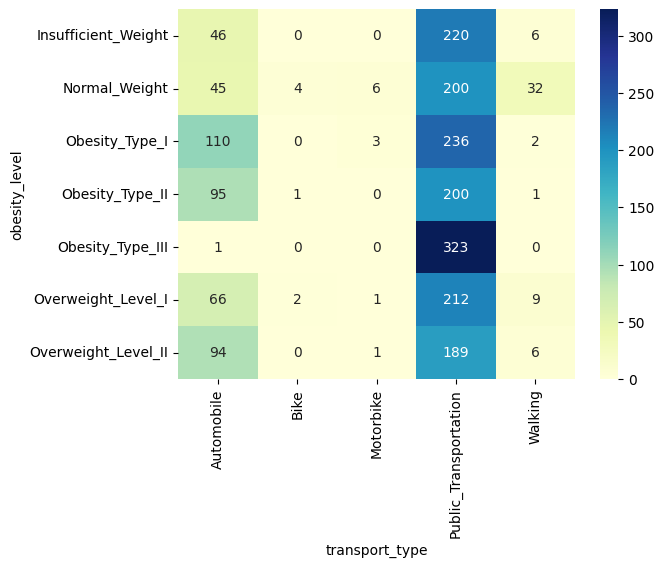

In [21]:
import seaborn as sns
sns.heatmap(table, annot=True, fmt='d', cmap='YlGnBu')



### Snacking VS Obesity Level

In [22]:
print(data['snacking'].unique())


['Sometimes' 'Frequently' 'Always' 'no']


In [23]:
crosstab = pd.crosstab(data['obesity_level'], data['snacking'])
crosstab_percent = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
crosstab

snacking,Always,Frequently,Sometimes,no
obesity_level,,,,
Insufficient_Weight,2,121,146,3
Normal_Weight,35,83,159,10
Obesity_Type_I,6,6,338,1
Obesity_Type_II,2,1,293,1
Obesity_Type_III,0,1,323,0
Overweight_Level_I,5,14,236,35
Overweight_Level_II,3,16,270,1


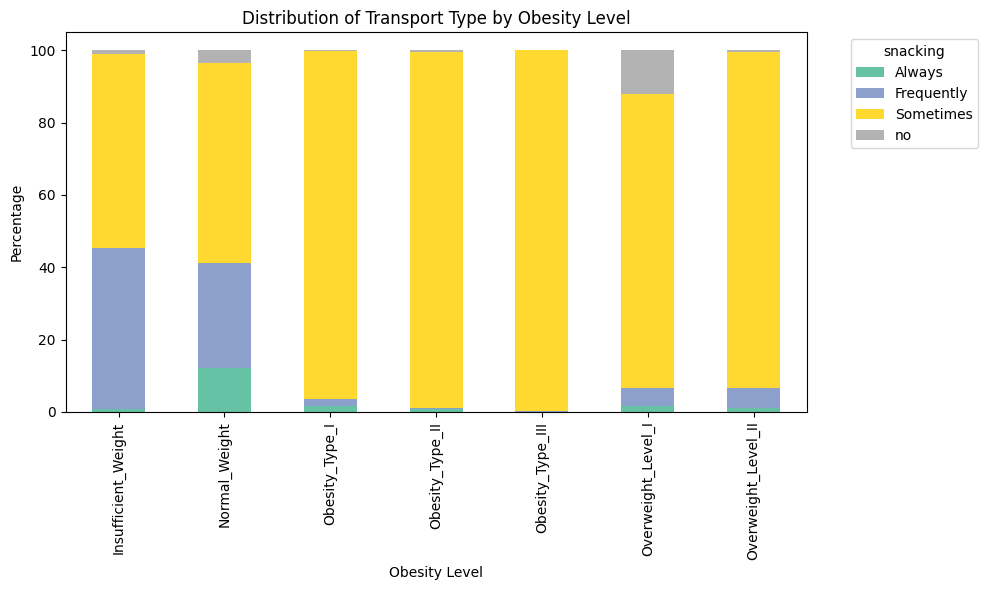

In [24]:
crosstab_percent.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Set2')
plt.title("Distribution of Transport Type by Obesity Level")
plt.ylabel("Percentage")
plt.xlabel("Obesity Level")
plt.legend(title="snacking", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()


In [25]:
chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"Chi2 statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4e}")

Chi2 statistic: 802.98
Degrees of freedom: 18
P-value: 7.3839e-159


<div dir='rtl'>
 <h2 style="color:rgb(61, 101, 141); border-bottom: 2px solid #3498db; padding-bottom: 5px; display: inline-block;">
   :استنتاج
  </h2>


- الامتناع التام عن الوجبات الخفيفة لا يعني وزناً صحياً

- Always أو Frequently في تناول الوجبات الخفيفة لا يترافق مباشرة مع مستويات سمنة عالية

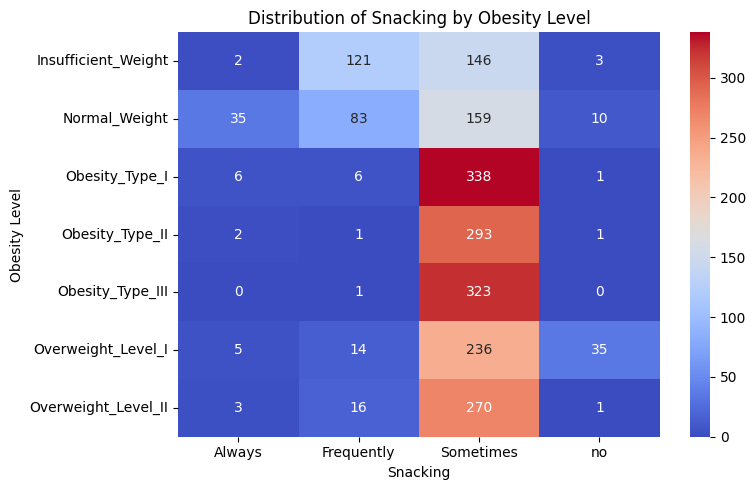

In [26]:
plt.figure(figsize=(8, 5))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='coolwarm')
plt.title("Distribution of Snacking by Obesity Level")
plt.xlabel("Snacking")
plt.ylabel("Obesity Level")
plt.tight_layout()
plt.show()

### Alcohol Intake VS Obesity Level

In [27]:
print(data['alcohol_intake'].unique())

['no' 'Sometimes' 'Frequently' 'Always']


In [28]:
crosstab = pd.crosstab(data['obesity_level'], data['alcohol_intake'])
crosstab

alcohol_intake,Always,Frequently,Sometimes,no
obesity_level,,,,
Insufficient_Weight,0,1,154,117
Normal_Weight,1,18,161,107
Obesity_Type_I,0,14,172,165
Obesity_Type_II,0,2,224,71
Obesity_Type_III,0,0,323,1
Overweight_Level_I,0,16,224,50
Overweight_Level_II,0,19,143,128


<div dir ='rtl'>



معظم من يعانون من السمنة يشربون الكحول أحياناً "Sometimes"



الامتناع عن الكحول "no" يرتبط أكثر بالأوزان الأقل


"Always" غير موجود فعلياً في أي فئة سمنة عالية


"Frequently" يظهر في مستويات سمنة خفيفة إلى متوسطة

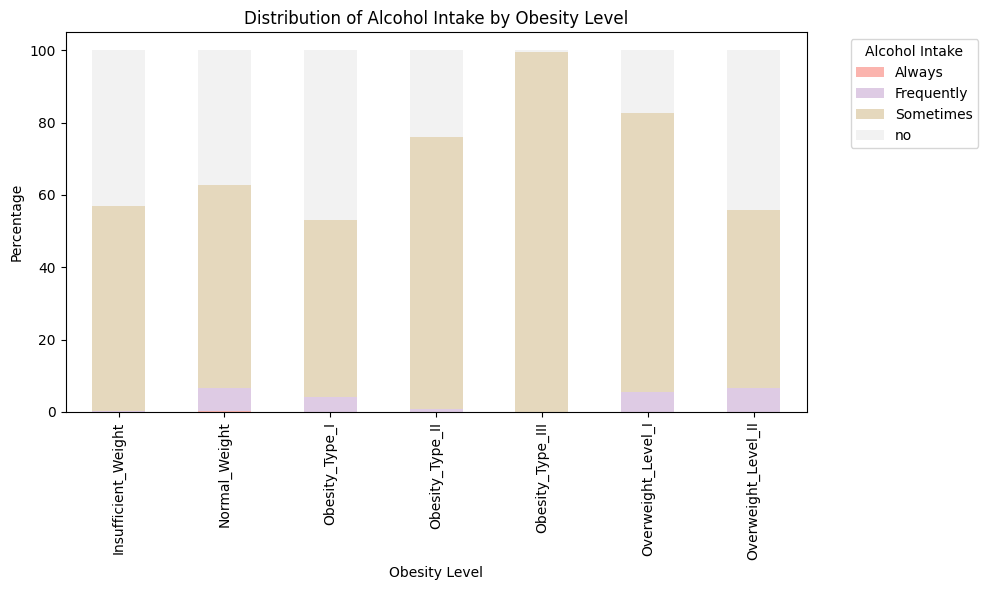

In [29]:
crosstab_percent = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
crosstab_percent.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Pastel1')
plt.title("Distribution of Alcohol Intake by Obesity Level")
plt.ylabel("Percentage")
plt.xlabel("Obesity Level")
plt.legend(title="Alcohol Intake", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [30]:
chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"Chi2 statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4e}")

Chi2 statistic: 338.58
Degrees of freedom: 18
P-value: 5.2872e-61


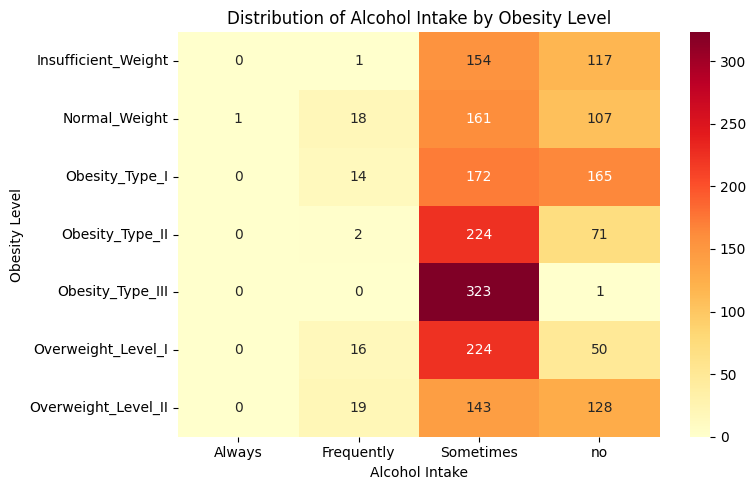

In [31]:
plt.figure(figsize=(8, 5))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlOrRd')
plt.title("Distribution of Alcohol Intake by Obesity Level")
plt.xlabel("Alcohol Intake")
plt.ylabel("Obesity Level")
plt.tight_layout()
plt.show()

### Calorie Monitoring VS Obesity Level

In [32]:
print(data['calorie_monitoring'].unique())

['no' 'yes']


In [33]:
crosstab = pd.crosstab(data["obesity_level"], data["calorie_monitoring"])
crosstab

calorie_monitoring,no,yes
obesity_level,,
Insufficient_Weight,250,22
Normal_Weight,257,30
Obesity_Type_I,349,2
Obesity_Type_II,296,1
Obesity_Type_III,324,0
Overweight_Level_I,253,37
Overweight_Level_II,286,4


<div dir='rtl'>

مراقبة السعرات نادرة جداً عند مستويات السمنة العالية


عدم المراقبة تهيمن بالكامل على الفئات ذات السمنة الشديدة


 كلما زاد الوزن، قلت احتمالية مراقبة السعرات


 "calorie_monitoring" قد يكون من أقوى العوامل الوقائية ضد السمنة

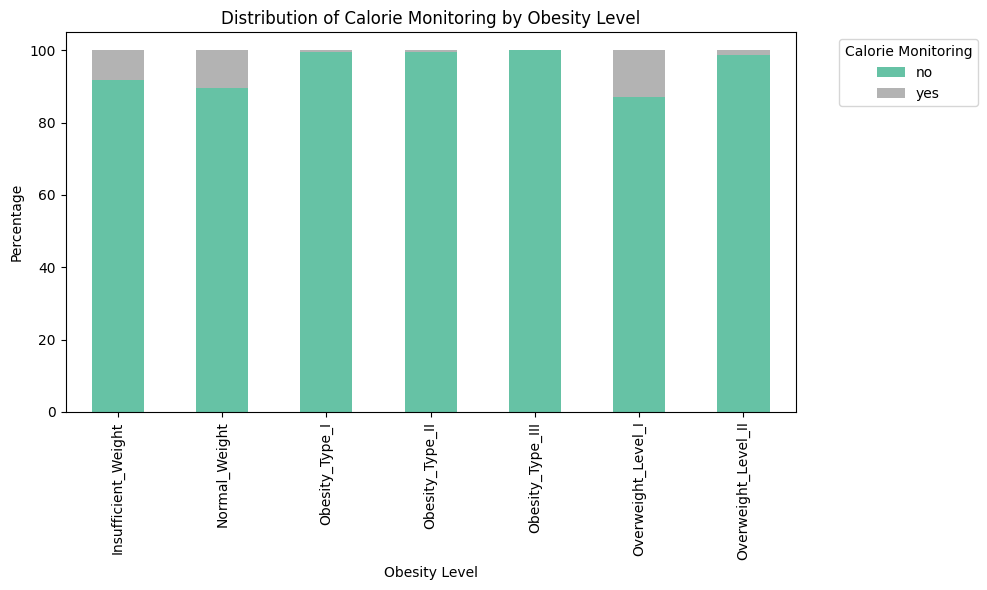

In [34]:
crosstab_percent = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
crosstab_percent.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Set2')
plt.title("Distribution of Calorie Monitoring by Obesity Level")
plt.ylabel("Percentage")
plt.xlabel("Obesity Level")
plt.legend(title="Calorie Monitoring", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [35]:
chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"Chi2 statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4e}")

Chi2 statistic: 123.02
Degrees of freedom: 6
P-value: 3.7732e-24


<div dir='rtl'>

الأشخاص الذين لا يراقبون السعرات الحرارية هم الأغلبية الساحقة في فئات السمنة العالية (Obesity_Type_I, II, III)

بينما الذين يراقبون السعرات يظهرون بنسبة أعلى في الفئات ذات الوزن الطبيعي أو الأقل

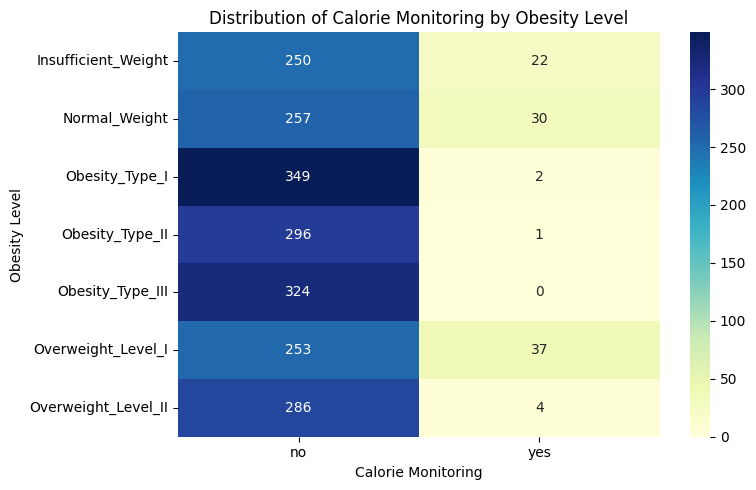

In [36]:
plt.figure(figsize=(8, 5))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlGnBu')
plt.title("Distribution of Calorie Monitoring by Obesity Level")
plt.xlabel("Calorie Monitoring")
plt.ylabel("Obesity Level")
plt.tight_layout()
plt.show()

### Smoking VS Obesity Level

In [37]:
print(data['smokes'].unique())

['no' 'yes']


In [38]:
crosstab =pd.crosstab(data['obesity_level'], data['smokes'])
crosstab

smokes,no,yes
obesity_level,,
Insufficient_Weight,271,1
Normal_Weight,274,13
Obesity_Type_I,345,6
Obesity_Type_II,282,15
Obesity_Type_III,323,1
Overweight_Level_I,287,3
Overweight_Level_II,285,5


<div dir='rtl'>

نسبة المدخنين منخفضة نسبياً، حتى في فئات السمنة المتقدمة:

أعلى نسبة مدخنين في Obesity_Type_II بنسبة حوالي 5% (15 من 297)

باقي الفئات المدخنون أقل من 5%

لا يظهر من الجدول أي علاقة واضحة بين التدخين ومستوى السمنة



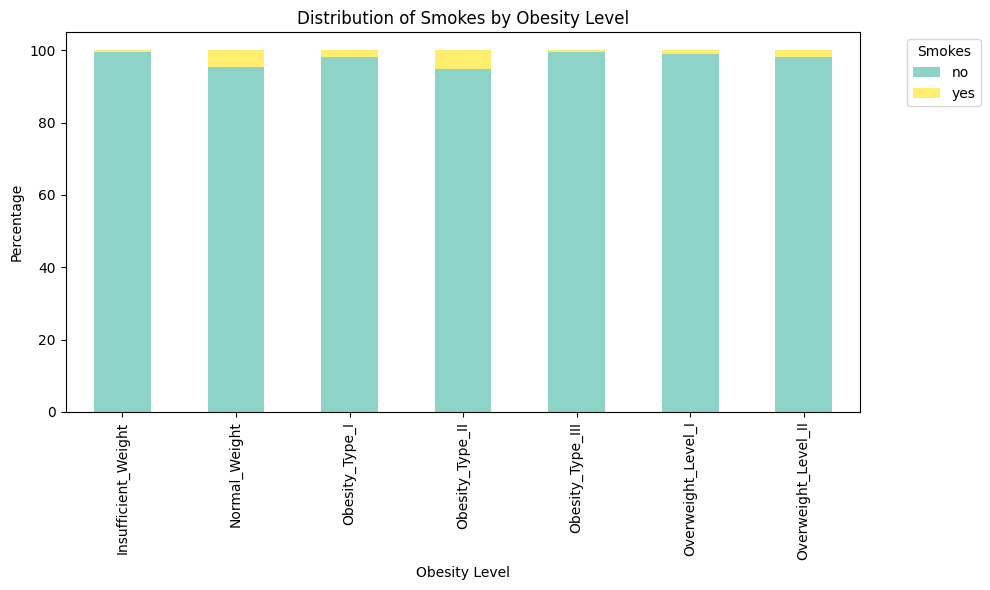

In [39]:
crosstab_percent = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
crosstab_percent.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Set3')
plt.title("Distribution of Smokes by Obesity Level")
plt.ylabel("Percentage")
plt.xlabel("Obesity Level")
plt.legend(title="Smokes", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [40]:
chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"Chi2 statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4e}")

Chi2 statistic: 32.14
Degrees of freedom: 6
P-value: 1.5354e-05


<div dir='rtl'>
قد يكون التدخين يؤثر على الوزن بطرق معقدة (مثلاً، بعض المدخنين قد ينقص وزنهم بسبب فقدان الشهية أو العكس)

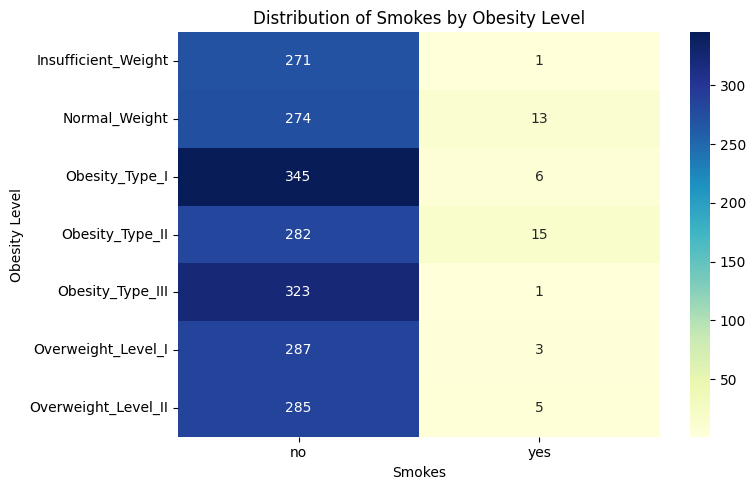

In [41]:
plt.figure(figsize=(8, 5))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlGnBu')
plt.title("Distribution of Smokes by Obesity Level")
plt.xlabel("Smokes")
plt.ylabel("Obesity Level")
plt.tight_layout()
plt.show()

### High Caloric Food VS Obesity Level

In [42]:
print(data['high_caloric_food'].unique())

['no' 'yes']


In [43]:
crosstab=pd.crosstab(data['obesity_level'], data['high_caloric_food'])
crosstab

high_caloric_food,no,yes
obesity_level,,
Insufficient_Weight,51,221
Normal_Weight,79,208
Obesity_Type_I,11,340
Obesity_Type_II,7,290
Obesity_Type_III,1,323
Overweight_Level_I,22,268
Overweight_Level_II,74,216


<div dir='rtl'>

الأغلبية في جميع مستويات السمنة يتناولون أطعمة عالية السعرات الحرارية

نلاحظ أن الفئات الأعلى في السمنة (Obesity_Type_I, II, III) فيها عدد أكبر بكثير من من يتناولون هذه الأطعمة مقارنة بمن لا يتناولون

الفئات الأقل في الوزن (Insufficient_Weight, Normal_Weight) نسبة المتناولين عالية أيضاً لكنها أقل مقارنة بفئات السمنة

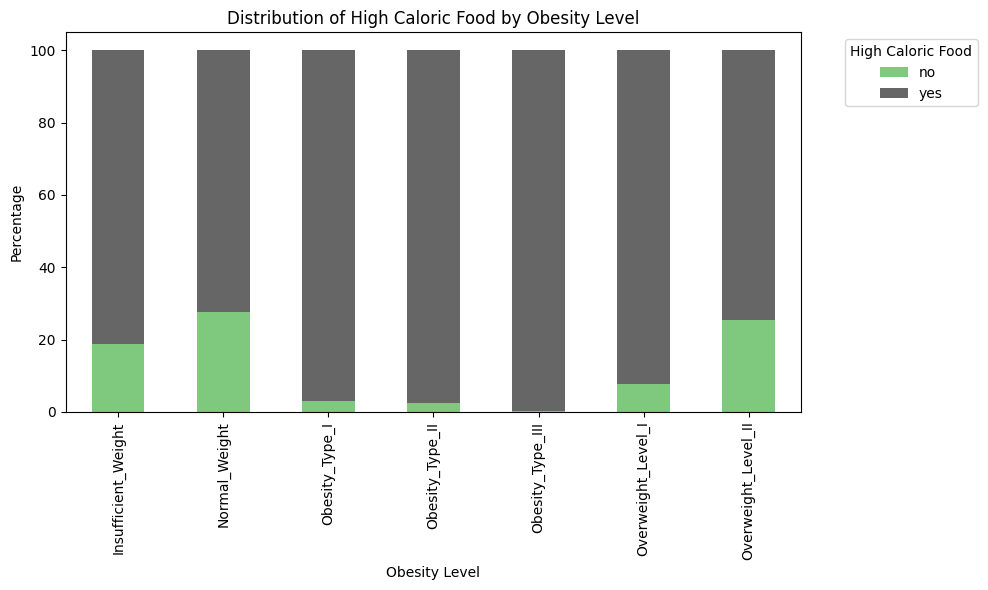

In [44]:
crosstab_percent = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
crosstab_percent.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Accent')
plt.title("Distribution of High Caloric Food by Obesity Level")
plt.ylabel("Percentage")
plt.xlabel("Obesity Level")
plt.legend(title="High Caloric Food", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [45]:
chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"Chi2 statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4e}")

Chi2 statistic: 233.34
Degrees of freedom: 6
P-value: 1.4822e-47


<div dir = 'rtl'>
 تناول الأطعمة عالية السعرات مرتبط بارتفاع مستويات السمنة، حيث أن الفئات ذات السمنة العالية تتناول هذه الأطعمة بنسب أكبر بكثير من الفئات الأقل وزناً

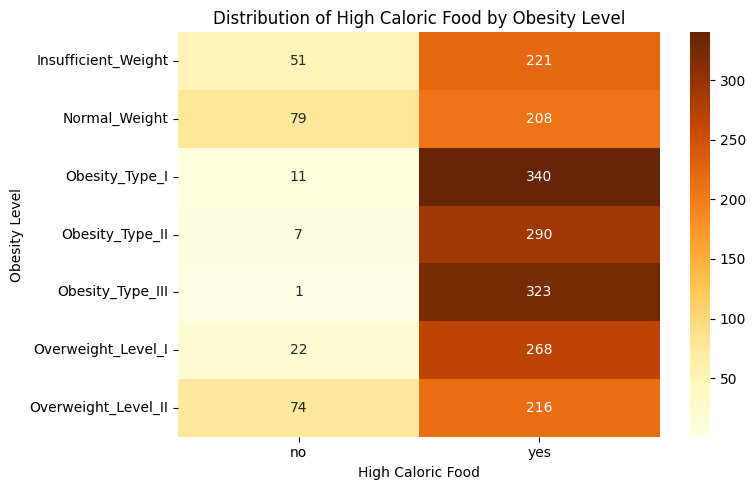

In [46]:
plt.figure(figsize=(8, 5))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlOrBr')
plt.title("Distribution of High Caloric Food by Obesity Level")
plt.xlabel("High Caloric Food")
plt.ylabel("Obesity Level")
plt.tight_layout()
plt.show()

### Family History OverWeight VS Obesity Level

In [47]:
print(data['family_history_overweight'].unique())

['yes' 'no']


In [48]:
crosstab = pd.crosstab(data['obesity_level'], data['family_history_overweight'])
crosstab

family_history_overweight,no,yes
obesity_level,,
Insufficient_Weight,146,126
Normal_Weight,132,155
Obesity_Type_I,7,344
Obesity_Type_II,1,296
Obesity_Type_III,0,324
Overweight_Level_I,81,209
Overweight_Level_II,18,272


<div dir = 'rtl'>

نسبة الأفراد الذين لديهم تاريخ عائلي للسمنة (yes) مرتفعة جداً في المجموعات ذات الوزن الزائد والسمنة (مثلاً Obesity_Type_I, Obesity_Type_II, Obesity_Type_III, Overweight_Level_I, و Overweight_Level_II)

على النقيض، في مجموعات الوزن الطبيعي أو الناقص الوزن (Insufficient_Weight و Normal_Weight)، النسب بين yes و no أكثر توازناً

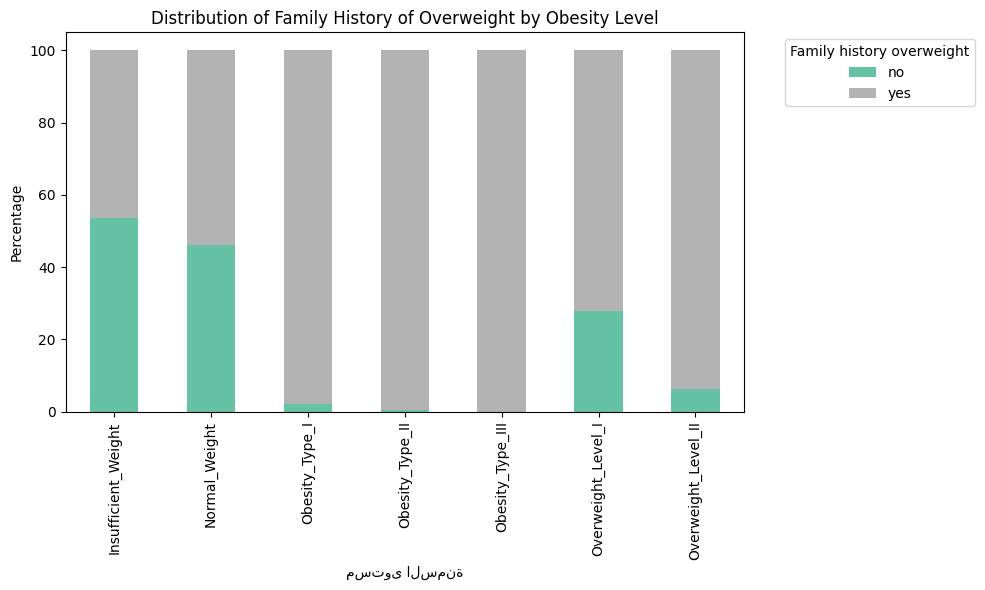

In [49]:
crosstab_percent = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
crosstab_percent.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Set2')
plt.title("Distribution of Family History of Overweight by Obesity Level")
plt.ylabel("Percentage")
plt.xlabel("مستوى السمنة")
plt.legend(title="Family history overweight", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [50]:
chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"Chi2 statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4e}")

Chi2 statistic: 621.98
Degrees of freedom: 6
P-value: 4.2280e-131


<div dir='rtl'>

الأشخاص الذين لديهم تاريخ عائلي للسمنة معرضون بشكل كبير جداً لأن يكونوا ضمن فئات:

Overweight_Level_I & II

Obesity_Type_I, II, III

في المقابل، الأشخاص دون تاريخ عائلي يميلون أكثر لأن يكونوا ضمن:

Normal_Weight

Insufficient_Weight

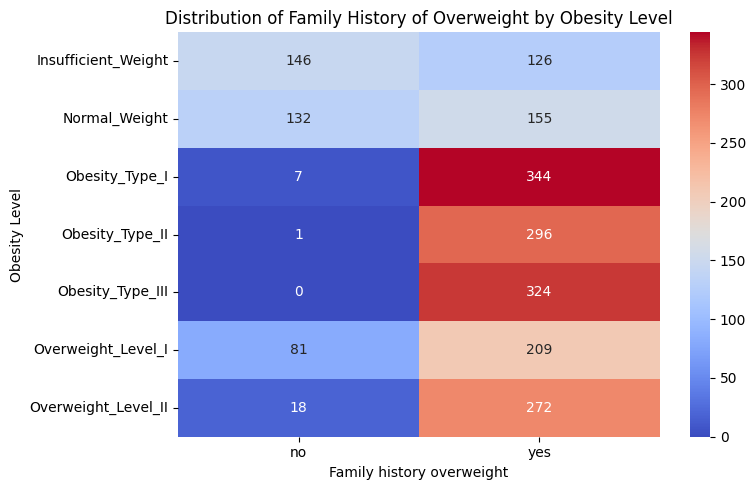

In [51]:
plt.figure(figsize=(8, 5))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='coolwarm')
plt.title("Distribution of Family History of Overweight by Obesity Level")
plt.xlabel("Family history overweight")
plt.ylabel("Obesity Level")
plt.tight_layout()
plt.show()

### Gender VS Obesity Level

In [52]:
print(data['gender'].unique())

['Female' 'Male']


In [53]:
crosstab = pd.crosstab(data['obesity_level'], data['gender'])
crosstab

gender,Female,Male
obesity_level,,
Insufficient_Weight,173,99
Normal_Weight,141,146
Obesity_Type_I,156,195
Obesity_Type_II,2,295
Obesity_Type_III,323,1
Overweight_Level_I,145,145
Overweight_Level_II,103,187


<div dir = 'rtl'>

Obesity_Type_III (السمنة المفرطة من النوع الثالث):

الإناث: 323

الذكور: 1

 يعني أن السمنة المفرطة من النوع الثالث تنتشر تقريباً فقط بين الإناث

*********************

 Obesity_Type_II (السمنة من النوع الثاني):

الإناث: 2

الذكور: 295

 عكس الحالة السابقة هذه الفئة تظهر بشكل شبه حصري عند الذكور

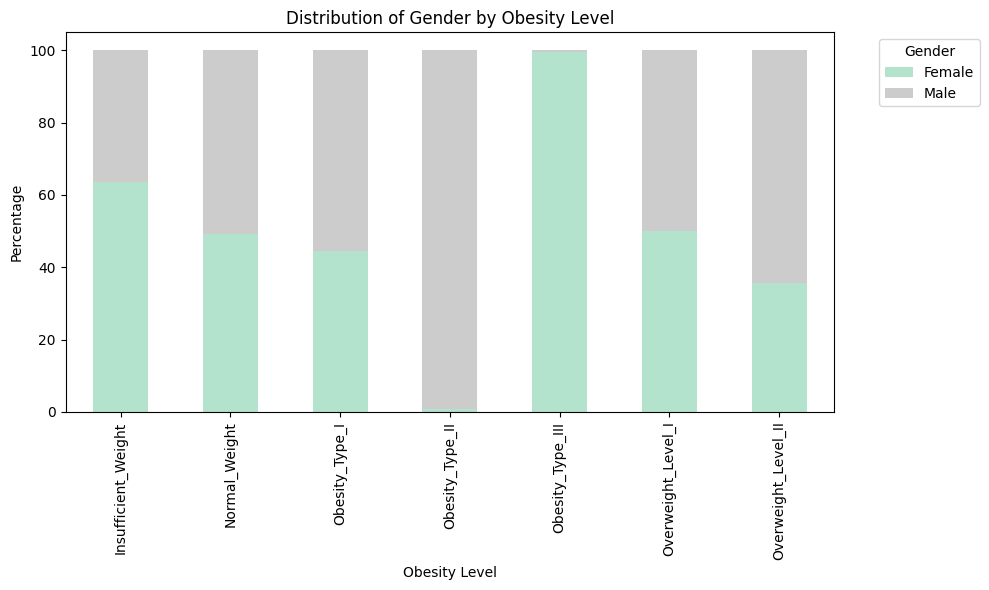

In [54]:
crosstab_percent = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
crosstab_percent.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Pastel2')
plt.title("Distribution of Gender by Obesity Level")
plt.ylabel("Percentage")
plt.xlabel("Obesity Level")
plt.legend(title="Gender", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [55]:
chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"Chi2 statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")

Chi2 statistic: 657.75
Degrees of freedom: 6
P-value: 0.0000


<div dir = 'rtl'>
 التباين الكبير بين الجنسين في الفئات شديدة السمنة (II و III) هو السبب الرئيسي للقيمة العالية 

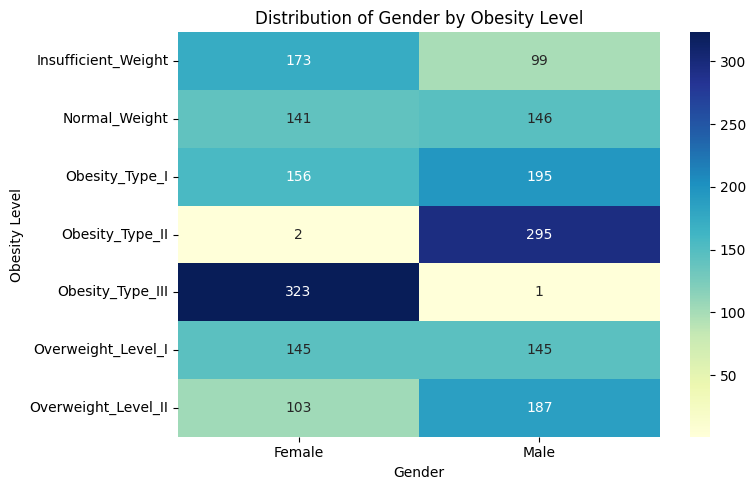

In [56]:
plt.figure(figsize=(8, 5))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlGnBu')
plt.title("Distribution of Gender by Obesity Level")
plt.xlabel("Gender")
plt.ylabel("Obesity Level")
plt.tight_layout()
plt.show()

## Data Distribution Analysis

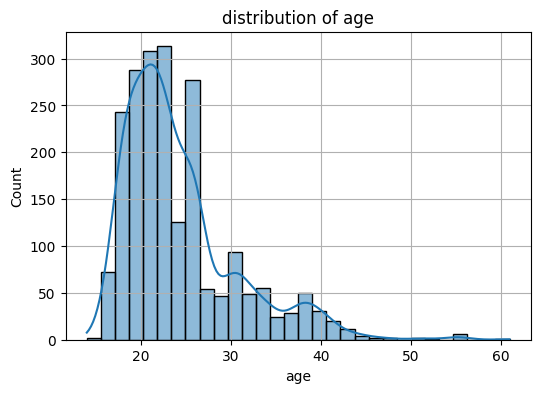

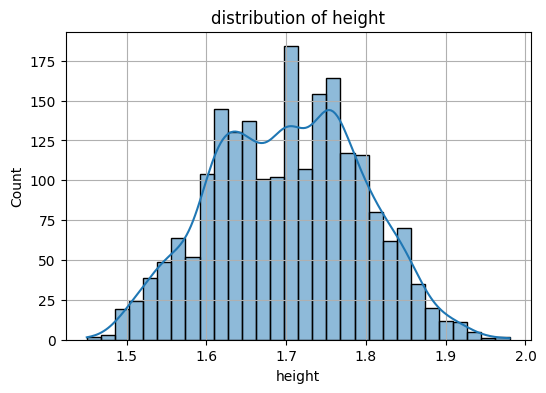

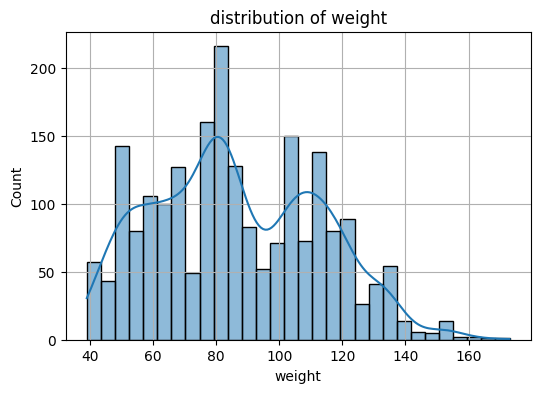

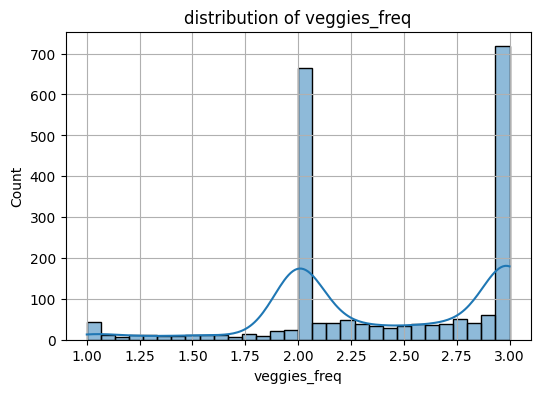

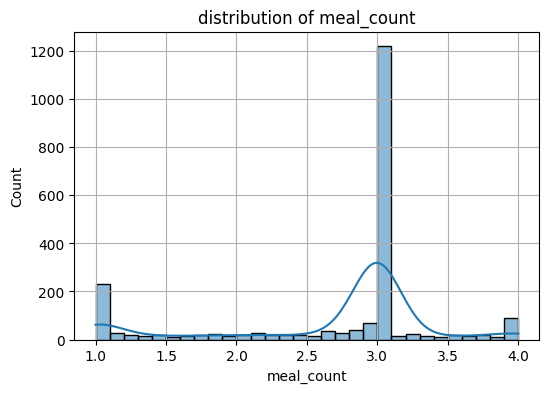

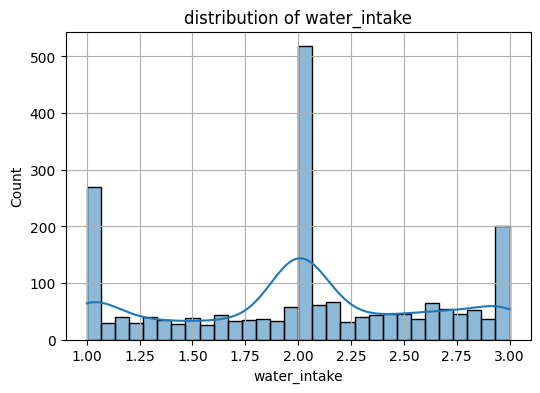

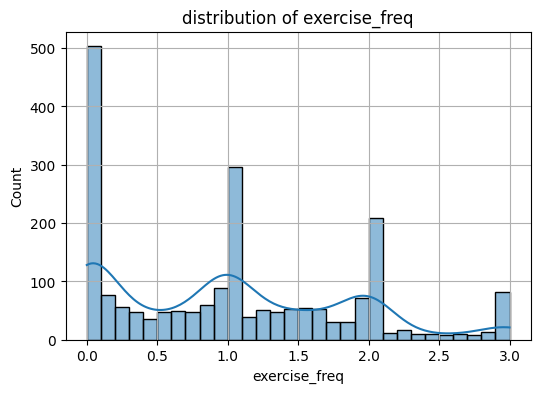

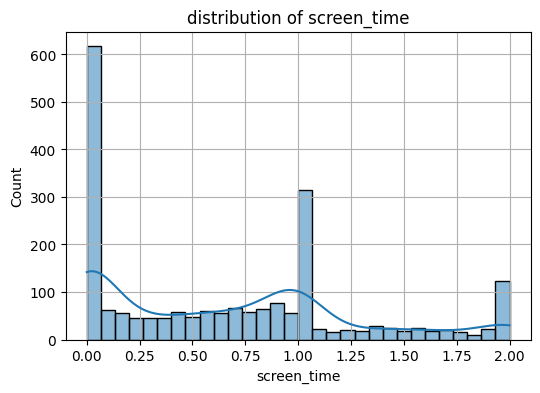

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
for col in numeric:
    plt.figure(figsize=(6, 4))
    sns.histplot(data[col], kde=True, bins=30)
    plt.title(f'distribution of {col}')
    plt.grid(True)
    plt.show()

توزع الطول والوزن لكل فئة

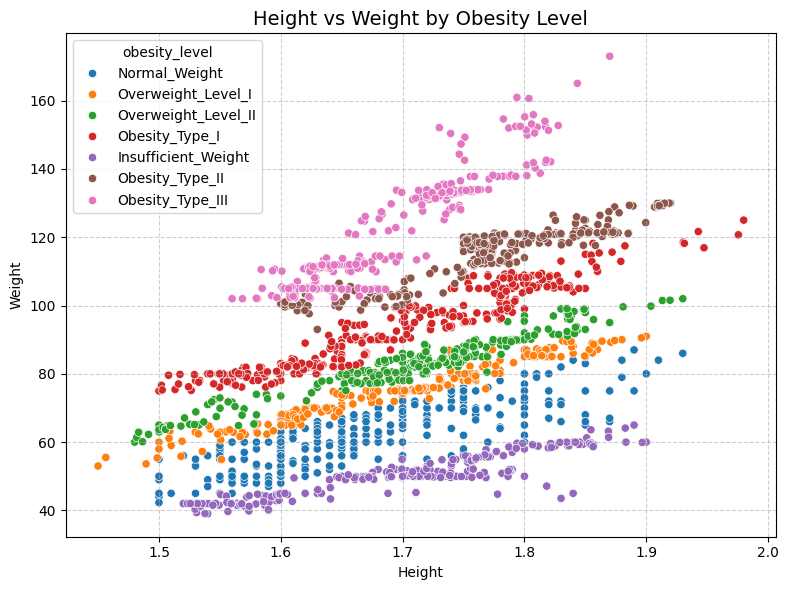

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x='height', y='weight', hue='obesity_level')
plt.title('Height vs Weight by Obesity Level', fontsize=14)
plt.xlabel('Height')
plt.ylabel('Weight')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


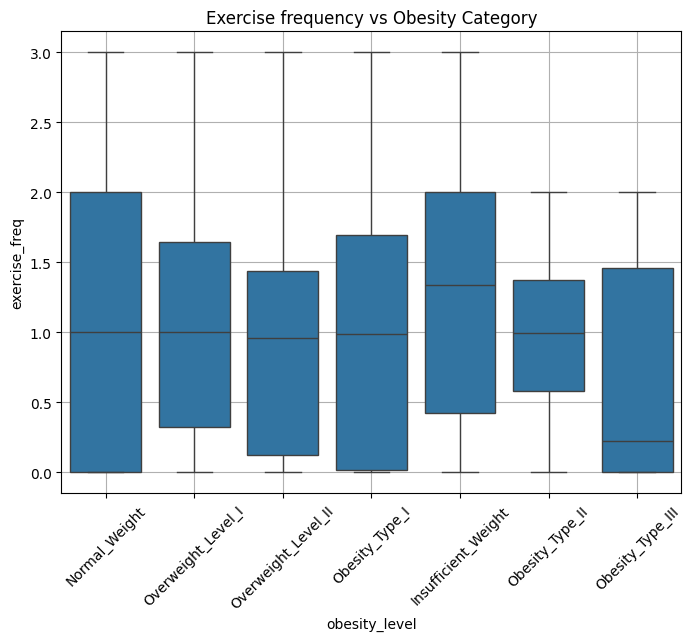

In [59]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=data, x='obesity_level', y='exercise_freq')
plt.title('Exercise frequency vs Obesity Category')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

توزع مستويات السمنة

In [60]:
import plotly.express as px

counts = data['obesity_level'].value_counts().reset_index()
counts.columns = ['obesity_level', 'count']

fig = px.bar(counts, x='obesity_level', y='count', title='Obesity Level Distribution')
fig.show()


***note***

we see here that the Obesity_Type_I is the most common type, and the Insufficient_Weight is the least 


#### Obesity Level Categories (Target Variable)



| Class No. | Class Name           | Meaning                                                                 |
|-----------|----------------------|-------------------------------------------------------------------------|
| 0         | Insufficient_Weight | Underweight — BMI is below the normal range                             |
| 1         | Normal_Weight        | Healthy weight — normal BMI, balanced habits                            |
| 2         | Overweight_Level_I   | Slightly above normal weight — pre-obese stage                          |
| 3         | Overweight_Level_II  | Noticeably above normal weight — close to obesity                       |
| 4         | Obesity_Type_I       | Obese Stage I — BMI around 30–34.9                                      |
| 5         | Obesity_Type_II      | Obese Stage II — BMI around 35–39.9                                     |
| 6         | Obesity_Type_III     | Obese Stage III (morbid) — BMI ≥ 40                                     |




In [61]:
data['BMI'] = (data['weight'] / (data['height'] ** 2)).round(2)

***note*** 

here we are adding a new feature the bmi it helps alot in obesity 

In [62]:
data.head()

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,obesity_level,BMI
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight,24.39
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight,24.24
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight,23.77
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I,26.85
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II,28.34


In [63]:
cols = list(data.columns)
cols.remove('BMI')
cols.insert(cols.index('transport_type') + 1, 'BMI')
data = data[cols]

In [64]:
data.head(20)

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,BMI,obesity_level
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,24.39,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,24.24,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,23.77,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,26.85,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,28.34,Overweight_Level_II
5,Male,29.0,1.62,53.0,no,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Automobile,20.20,Normal_Weight
6,Female,23.0,1.50,55.0,yes,yes,3.0,3.0,Sometimes,no,2.0,no,1.0,0.0,Sometimes,Motorbike,24.44,Normal_Weight
7,Male,22.0,1.64,53.0,no,no,2.0,3.0,Sometimes,no,2.0,no,3.0,0.0,Sometimes,Public_Transportation,19.71,Normal_Weight
8,Male,24.0,1.78,64.0,yes,yes,3.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Frequently,Public_Transportation,20.20,Normal_Weight
9,Male,22.0,1.72,68.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,no,Public_Transportation,22.99,Normal_Weight


In [65]:
binary_cols = ['family_history_overweight', 'high_caloric_food', 'smokes', 'calorie_monitoring']

for col in binary_cols:
    data[col] = data[col].map({'yes': 1, 'no': 0})


In [66]:
data.head()

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,BMI,obesity_level
0,Female,21.0,1.62,64.0,1,0,2.0,3.0,Sometimes,0,2.0,0,0.0,1.0,no,Public_Transportation,24.39,Normal_Weight
1,Female,21.0,1.52,56.0,1,0,3.0,3.0,Sometimes,1,3.0,1,3.0,0.0,Sometimes,Public_Transportation,24.24,Normal_Weight
2,Male,23.0,1.80,77.0,1,0,2.0,3.0,Sometimes,0,2.0,0,2.0,1.0,Frequently,Public_Transportation,23.77,Normal_Weight
3,Male,27.0,1.80,87.0,0,0,3.0,3.0,Sometimes,0,2.0,0,2.0,0.0,Frequently,Walking,26.85,Overweight_Level_I
4,Male,22.0,1.78,89.8,0,0,2.0,1.0,Sometimes,0,2.0,0,0.0,0.0,Sometimes,Public_Transportation,28.34,Overweight_Level_II


In [67]:
data['risk_factors'] = (
    data['smokes'] +
    data['high_caloric_food'] +
    data['calorie_monitoring'].apply(lambda x: 0 if x == 1 else 1) +
    (data['exercise_freq'] < 1).astype(int)
)

***note***

here we added a new feature the risk factors with takes into account the smokes and high_caloric_food and calorie_monitoring and exercise_freq which indicates how high is the preson risk 

In [68]:
data['risk_factors'].value_counts()

risk_factors
2    1003
3     898
1     164
0      28
4      18
Name: count, dtype: int64

In [69]:
scaler = MinMaxScaler()
data[['veggies_freq_norm', 'meal_count_norm', 'water_intake_norm']] = scaler.fit_transform(
    data[['veggies_freq', 'meal_count', 'water_intake']]
)

In [70]:
data['nutrition_score'] = ((
    data['veggies_freq_norm'] +
    data['meal_count_norm'] +
    data['water_intake_norm']
) / 3).round(2)

In [71]:
data.drop(columns=['veggies_freq_norm', 'meal_count_norm', 'water_intake_norm'], inplace=True)


In [72]:
print(data[['veggies_freq', 'meal_count', 'water_intake', 'nutrition_score']].head())


   veggies_freq  meal_count  water_intake  nutrition_score
0           2.0         3.0           2.0             0.56
1           3.0         3.0           3.0             0.89
2           2.0         3.0           2.0             0.56
3           3.0         3.0           2.0             0.72
4           2.0         1.0           2.0             0.33


***note***

here we added a new feature the Nutrition score with takes into account the veggies_freq and meal_count and water_intake which means how healthy the person is, but before we did it we used MinMaxScaler to normalize the features before combining them into a new feature so can all the features contribute equally when we compute the average 

In [73]:
data.head(20)

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,BMI,obesity_level,risk_factors,nutrition_score
0,Female,21.0,1.62,64.0,1,0,2.0,3.0,Sometimes,0,2.0,0,0.0,1.0,no,Public_Transportation,24.39,Normal_Weight,2,0.56
1,Female,21.0,1.52,56.0,1,0,3.0,3.0,Sometimes,1,3.0,1,3.0,0.0,Sometimes,Public_Transportation,24.24,Normal_Weight,1,0.89
2,Male,23.0,1.80,77.0,1,0,2.0,3.0,Sometimes,0,2.0,0,2.0,1.0,Frequently,Public_Transportation,23.77,Normal_Weight,1,0.56
3,Male,27.0,1.80,87.0,0,0,3.0,3.0,Sometimes,0,2.0,0,2.0,0.0,Frequently,Walking,26.85,Overweight_Level_I,1,0.72
4,Male,22.0,1.78,89.8,0,0,2.0,1.0,Sometimes,0,2.0,0,0.0,0.0,Sometimes,Public_Transportation,28.34,Overweight_Level_II,2,0.33
5,Male,29.0,1.62,53.0,0,1,2.0,3.0,Sometimes,0,2.0,0,0.0,0.0,Sometimes,Automobile,20.20,Normal_Weight,3,0.56
6,Female,23.0,1.50,55.0,1,1,3.0,3.0,Sometimes,0,2.0,0,1.0,0.0,Sometimes,Motorbike,24.44,Normal_Weight,2,0.72
7,Male,22.0,1.64,53.0,0,0,2.0,3.0,Sometimes,0,2.0,0,3.0,0.0,Sometimes,Public_Transportation,19.71,Normal_Weight,1,0.56
8,Male,24.0,1.78,64.0,1,1,3.0,3.0,Sometimes,0,2.0,0,1.0,1.0,Frequently,Public_Transportation,20.20,Normal_Weight,2,0.72
9,Male,22.0,1.72,68.0,1,1,2.0,3.0,Sometimes,0,2.0,0,1.0,1.0,no,Public_Transportation,22.99,Normal_Weight,2,0.56


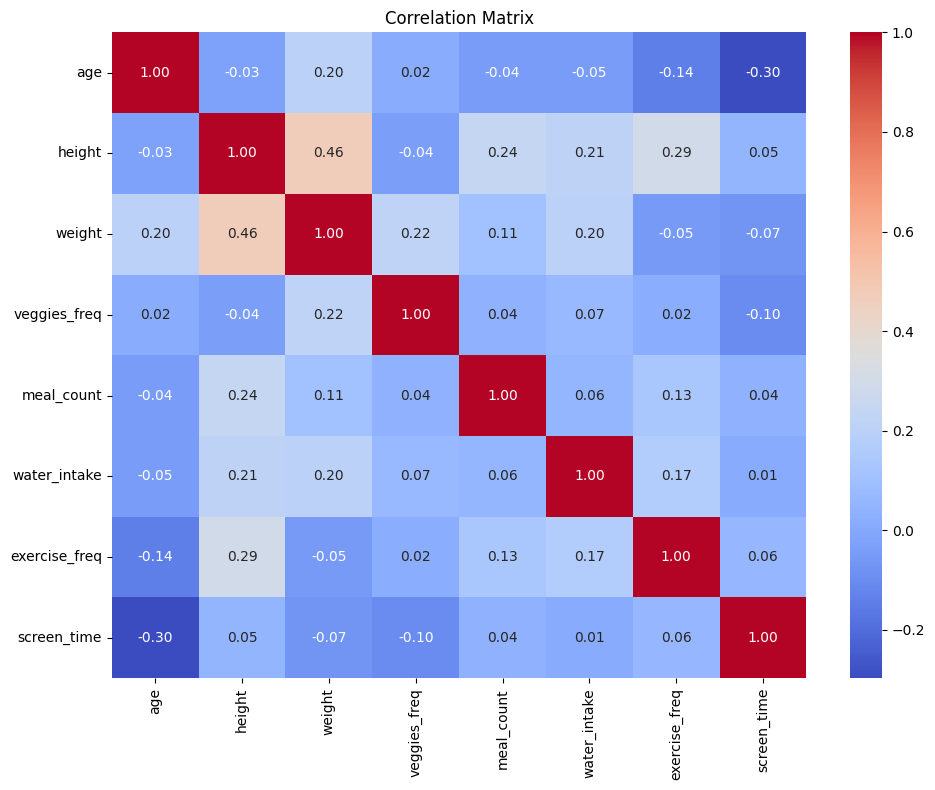

In [74]:
plt.figure(figsize=(10, 8))
corr = numeric.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()


In [75]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 24


In [76]:
duplicates = data[data.duplicated(keep=False)]
print(duplicates)

     gender   age  height  weight  family_history_overweight  \
97   Female  21.0    1.52    42.0                          0   
98   Female  21.0    1.52    42.0                          0   
105  Female  25.0    1.57    55.0                          0   
106  Female  25.0    1.57    55.0                          0   
145    Male  21.0    1.62    70.0                          0   
174    Male  21.0    1.62    70.0                          0   
179    Male  21.0    1.62    70.0                          0   
184    Male  21.0    1.62    70.0                          0   
208  Female  22.0    1.69    65.0                          1   
209  Female  22.0    1.69    65.0                          1   
282  Female  18.0    1.62    55.0                          1   
295  Female  16.0    1.66    58.0                          0   
309  Female  16.0    1.66    58.0                          0   
443    Male  18.0    1.72    53.0                          1   
460  Female  18.0    1.62    55.0       

In [77]:
data = data.drop_duplicates()
data.shape

(2087, 20)

In [78]:
data = data[[col for col in data.columns if col != 'obesity_level'] + ['obesity_level']]

In [79]:
data.head()

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,BMI,risk_factors,nutrition_score,obesity_level
0,Female,21.0,1.62,64.0,1,0,2.0,3.0,Sometimes,0,2.0,0,0.0,1.0,no,Public_Transportation,24.39,2,0.56,Normal_Weight
1,Female,21.0,1.52,56.0,1,0,3.0,3.0,Sometimes,1,3.0,1,3.0,0.0,Sometimes,Public_Transportation,24.24,1,0.89,Normal_Weight
2,Male,23.0,1.80,77.0,1,0,2.0,3.0,Sometimes,0,2.0,0,2.0,1.0,Frequently,Public_Transportation,23.77,1,0.56,Normal_Weight
3,Male,27.0,1.80,87.0,0,0,3.0,3.0,Sometimes,0,2.0,0,2.0,0.0,Frequently,Walking,26.85,1,0.72,Overweight_Level_I
4,Male,22.0,1.78,89.8,0,0,2.0,1.0,Sometimes,0,2.0,0,0.0,0.0,Sometimes,Public_Transportation,28.34,2,0.33,Overweight_Level_II


## OutLiers


[PennState](https://online.stat.psu.edu/stat200/lesson/3/3.2)

 طريقة علمية إحصائية لاكتشاف القيم الشاذة وهي تعتمد على الفرق بين الربعين مفيدة عندما تكون البيانات متوزعة بشكل جيد كحالتنا حيث الرقم 1.5 معامل حسابي شائع موضح سبب استخدامه في هذا الموقع 
 
 [built in](https://builtin.com/articles/1-5-iqr-rule)

ولكن إذا أردنا القيم الشاذة بوضوح نستخدم المعامل 3

In [80]:
for col in numeric.columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = data[(data[col] < Q1 - 3 * IQR) | (data[col] > Q3 + 3 * IQR)]
    print(f"{col}: Number of outliers = {outliers.shape[0]}")


age: Number of outliers = 17
height: Number of outliers = 0
weight: Number of outliers = 0
veggies_freq: Number of outliers = 0
meal_count: Number of outliers = 426
water_intake: Number of outliers = 0
exercise_freq: Number of outliers = 0
screen_time: Number of outliers = 0


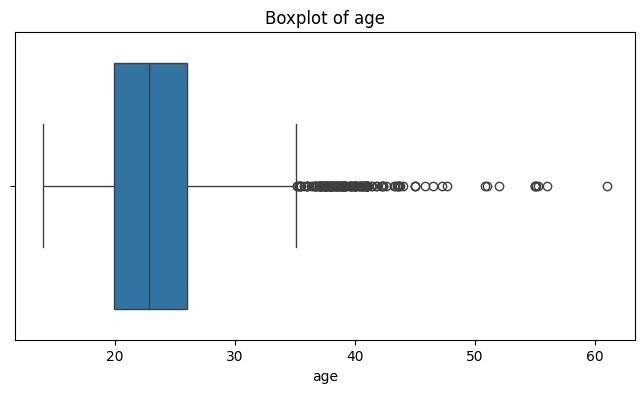

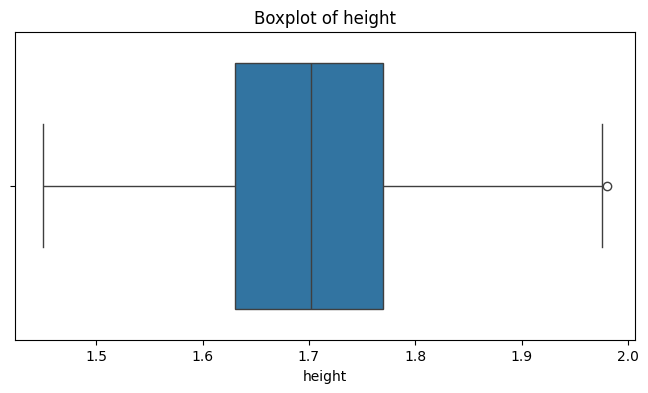

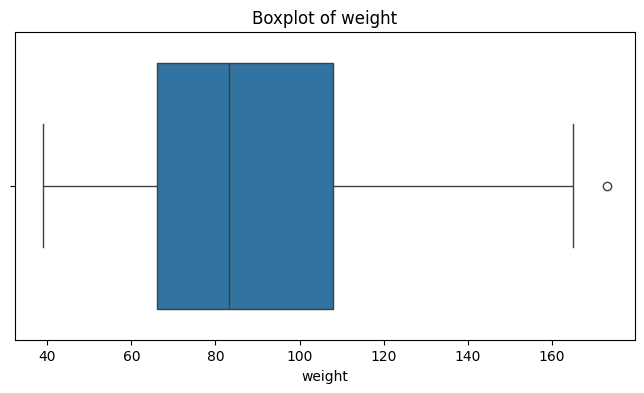

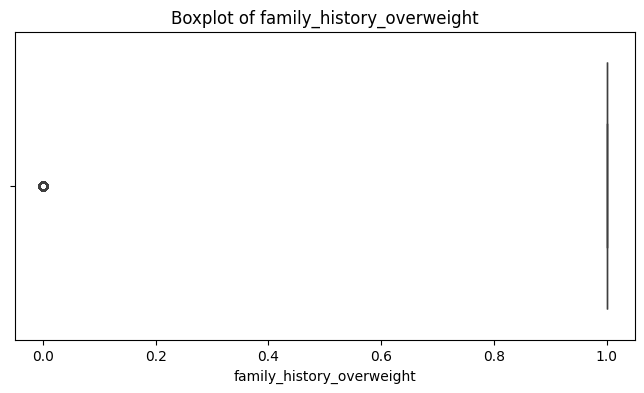

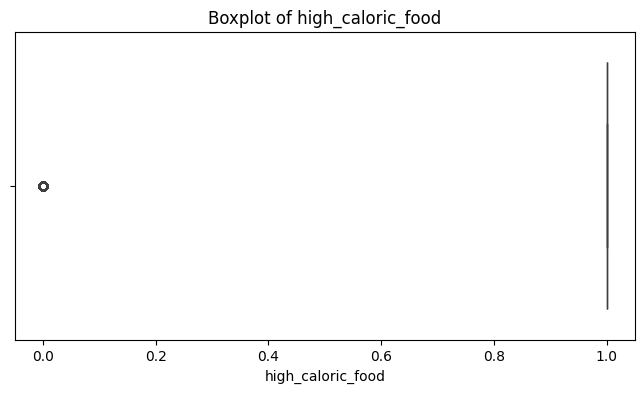

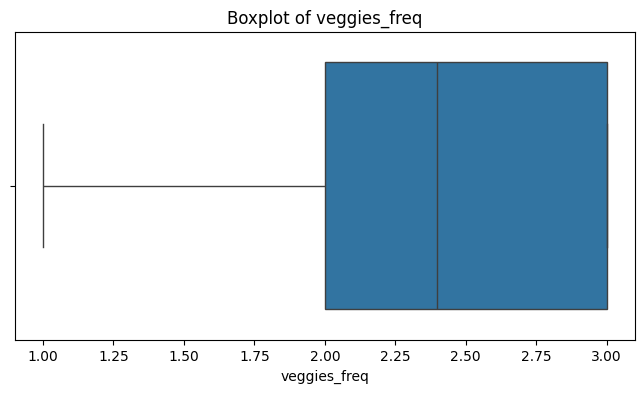

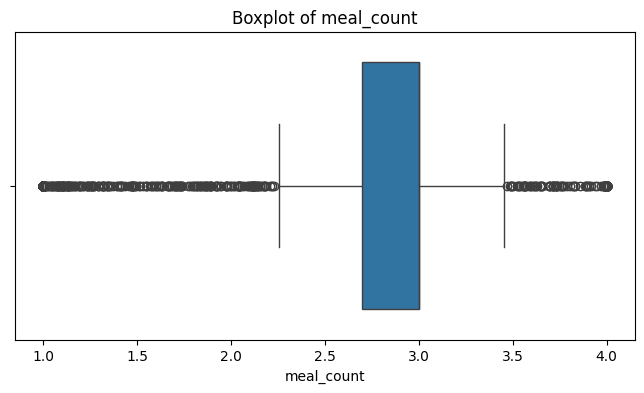

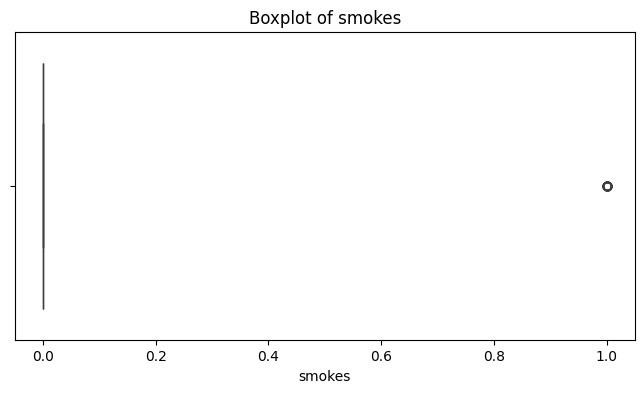

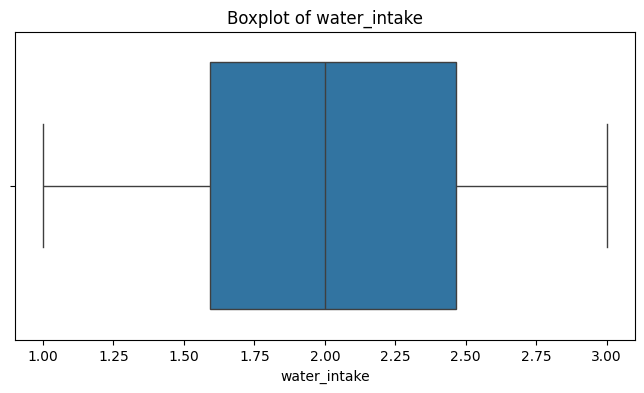

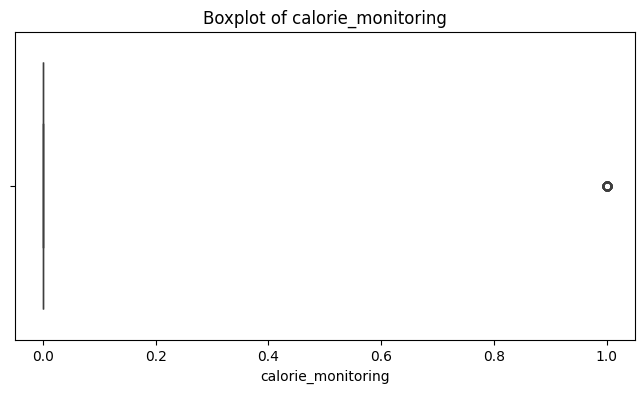

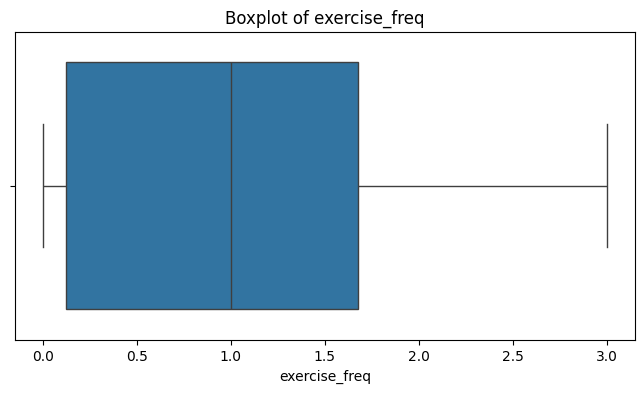

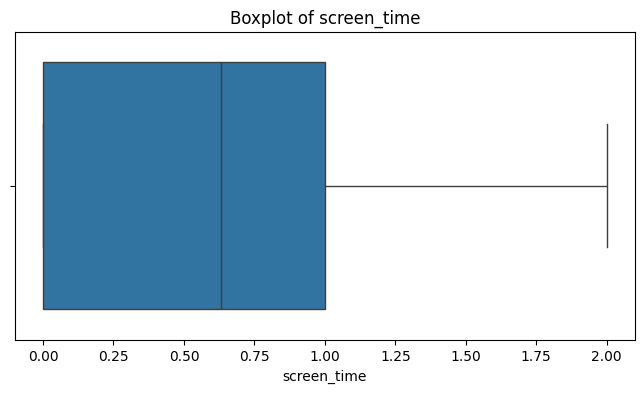

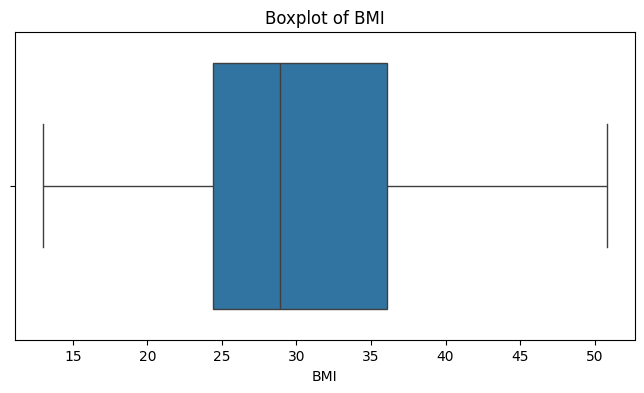

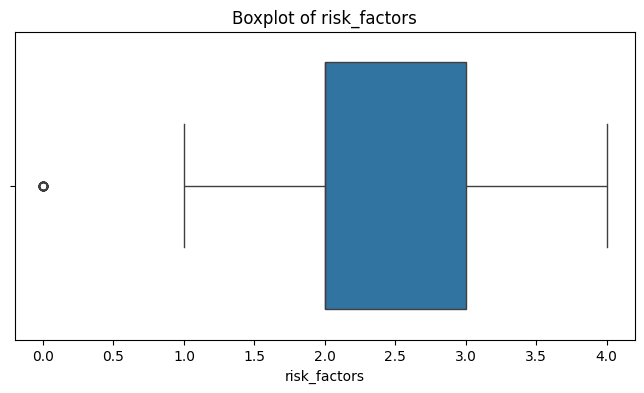

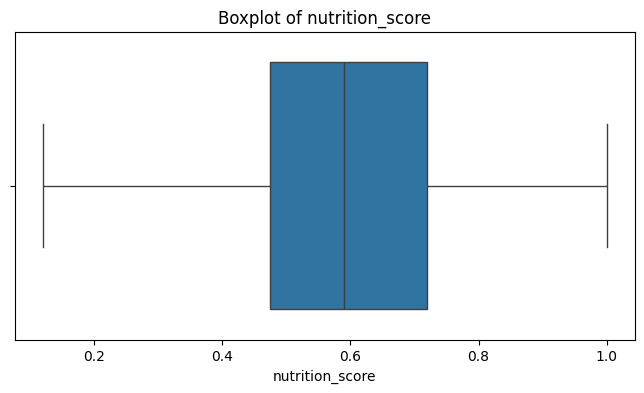

In [81]:

numeric_cols = data.select_dtypes(include=['int64', 'float64']).columns


for col in numeric_cols:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=data[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


In [82]:
print (data ['age'].max())
print (data ['age'].min())

61.0
14.0


In [83]:
print(data['height'].max())
print(data['height'].min())

1.98
1.45


In [84]:
print (data ['weight'].max())
print (data ['weight'].min())

173.0
39.0


In [85]:
under_40 = data['weight']<40


under_40.sum()


5

In [86]:
samples_under_40 = data[under_40]
samples_under_40

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,BMI,risk_factors,nutrition_score,obesity_level
395,Female,20.000000,1.540000,39.000000,1,1,1.000000,3.000000,Sometimes,0,2.000000,0,3.000000,2.000000,Sometimes,Public_Transportation,16.44,2,0.39,Insufficient_Weight
588,Female,18.530840,1.573816,39.850137,0,1,1.214980,1.717608,Sometimes,0,1.179942,0,0.684739,2.000000,Sometimes,Public_Transportation,16.09,3,0.15,Insufficient_Weight
589,Female,19.948140,1.530884,39.371523,0,1,1.522001,3.000000,Sometimes,0,1.981260,0,2.306844,0.720454,Sometimes,Public_Transportation,16.80,2,0.47,Insufficient_Weight
636,Female,19.054008,1.556611,39.695295,0,1,1.889199,2.217651,Sometimes,0,2.013605,0,2.075293,1.683261,Sometimes,Public_Transportation,16.38,2,0.45,Insufficient_Weight
725,Female,19.994543,1.537739,39.101805,0,1,1.118436,3.000000,Sometimes,0,1.997744,0,2.432443,1.626194,Sometimes,Public_Transportation,16.54,2,0.41,Insufficient_Weight


In [87]:
print (data['meal_count'].max())
print (data['meal_count'].min())


4.0
1.0


In [88]:
data.head()

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,BMI,risk_factors,nutrition_score,obesity_level
0,Female,21.0,1.62,64.0,1,0,2.0,3.0,Sometimes,0,2.0,0,0.0,1.0,no,Public_Transportation,24.39,2,0.56,Normal_Weight
1,Female,21.0,1.52,56.0,1,0,3.0,3.0,Sometimes,1,3.0,1,3.0,0.0,Sometimes,Public_Transportation,24.24,1,0.89,Normal_Weight
2,Male,23.0,1.80,77.0,1,0,2.0,3.0,Sometimes,0,2.0,0,2.0,1.0,Frequently,Public_Transportation,23.77,1,0.56,Normal_Weight
3,Male,27.0,1.80,87.0,0,0,3.0,3.0,Sometimes,0,2.0,0,2.0,0.0,Frequently,Walking,26.85,1,0.72,Overweight_Level_I
4,Male,22.0,1.78,89.8,0,0,2.0,1.0,Sometimes,0,2.0,0,0.0,0.0,Sometimes,Public_Transportation,28.34,2,0.33,Overweight_Level_II


# Machine Learning Section

## Data Preparation (Train-Test Split + Encoding)

In [89]:
df = pd.read_csv('Estimation of obesity levels/data_cleaned.csv')
#df = pd.read_csv('data_cleaned.csv')

In [90]:
df.shape

(2087, 20)

In [91]:
df.head()

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,BMI,risk_factors,nutrition_score,obesity_level
0,Female,21.0,1.62,64.0,1,0,2.0,3.0,Sometimes,0,2.0,0,0.0,1.0,no,Public_Transportation,24.39,2,0.56,Normal_Weight
1,Female,21.0,1.52,56.0,1,0,3.0,3.0,Sometimes,1,3.0,1,3.0,0.0,Sometimes,Public_Transportation,24.24,1,0.89,Normal_Weight
2,Male,23.0,1.80,77.0,1,0,2.0,3.0,Sometimes,0,2.0,0,2.0,1.0,Frequently,Public_Transportation,23.77,1,0.56,Normal_Weight
3,Male,27.0,1.80,87.0,0,0,3.0,3.0,Sometimes,0,2.0,0,2.0,0.0,Frequently,Walking,26.85,1,0.72,Overweight_Level_I
4,Male,22.0,1.78,89.8,0,0,2.0,1.0,Sometimes,0,2.0,0,0.0,0.0,Sometimes,Public_Transportation,28.34,2,0.33,Overweight_Level_II


In [92]:
# numerical_df, categorical_df = get_types(df)
# numerical = numerical_df
# categorical = categorical_df
# # numerical= df[numerical_df]
# # categorical = df[categorical_df]

categorical = ['gender','snacking','alcohol_intake','transport_type']
numerical = ['age','height','weight','veggies_freq','meal_count','water_intake','exercise_freq','screen_time','BMI','nutrition_score','family_history_overweight','high_caloric_food','smokes','calorie_monitoring','risk_factors']
target = ['obesity_level']

In [93]:
categorical

['gender', 'snacking', 'alcohol_intake', 'transport_type']

In [94]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('scaler', MinMaxScaler())
        ]), numerical),

        ('cat', Pipeline(steps=[
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical)
    ]
)


In [95]:
label_encoder = LabelEncoder()

df['obesity_level'] = label_encoder.fit_transform(df['obesity_level'])

In [96]:
for encoded_value in df['obesity_level'].unique():
    original_value = label_encoder.inverse_transform([encoded_value])[0]
    print(f"{encoded_value} -> {original_value}")


1 -> Normal_Weight
5 -> Overweight_Level_I
6 -> Overweight_Level_II
2 -> Obesity_Type_I
0 -> Insufficient_Weight
3 -> Obesity_Type_II
4 -> Obesity_Type_III


In [97]:
X = df.drop(['obesity_level'], axis=1)
y = df['obesity_level']

In [98]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Baseline Model 

In [99]:
df.head()

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,BMI,risk_factors,nutrition_score,obesity_level
0,Female,21.0,1.62,64.0,1,0,2.0,3.0,Sometimes,0,2.0,0,0.0,1.0,no,Public_Transportation,24.39,2,0.56,1
1,Female,21.0,1.52,56.0,1,0,3.0,3.0,Sometimes,1,3.0,1,3.0,0.0,Sometimes,Public_Transportation,24.24,1,0.89,1
2,Male,23.0,1.80,77.0,1,0,2.0,3.0,Sometimes,0,2.0,0,2.0,1.0,Frequently,Public_Transportation,23.77,1,0.56,1
3,Male,27.0,1.80,87.0,0,0,3.0,3.0,Sometimes,0,2.0,0,2.0,0.0,Frequently,Walking,26.85,1,0.72,5
4,Male,22.0,1.78,89.8,0,0,2.0,1.0,Sometimes,0,2.0,0,0.0,0.0,Sometimes,Public_Transportation,28.34,2,0.33,6


In [100]:
poly_model = Pipeline([
    ('preprocessor', preprocessor),  
    ('logreg', LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000))
])
poly_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   MinMaxScaler())]),
                                                  ['age', 'height', 'weight',
                                                   'veggies_freq', 'meal_count',
                                                   'water_intake',
                                                   'exercise_freq',
                                                   'screen_time', 'BMI',
                                                   'nutrition_score',
                                                   'family_history_overweight',
                                                   'high_caloric_food',
                                                   'smokes',
                                                   'calorie_monitoring',
                                                   'risk_factors']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'snacking',
                                                   'alcohol_intake',
                                                   'transport_type'])])),
                ('logreg',
                 LogisticRegression(max_iter=1000, multi_class='multinomial'))])

In [101]:
y_pred = poly_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.777511961722488


In [102]:
cm = confusion_matrix(y_test, y_pred)
class_names = label_encoder.classes_
class_names

array(['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I',
       'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I',
       'Overweight_Level_II'], dtype=object)

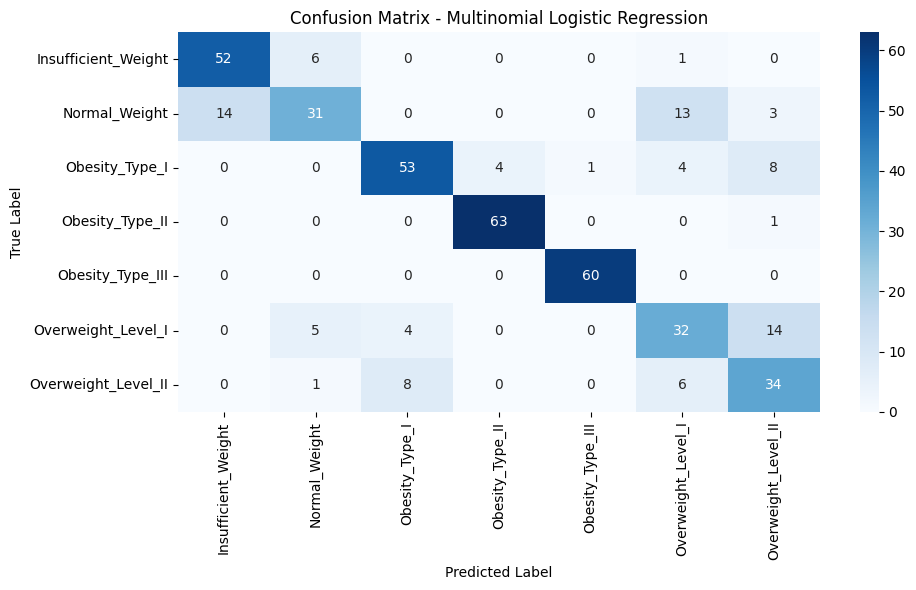

In [103]:
plt.figure(figsize=(10, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Multinomial Logistic Regression')
plt.tight_layout()
plt.show()

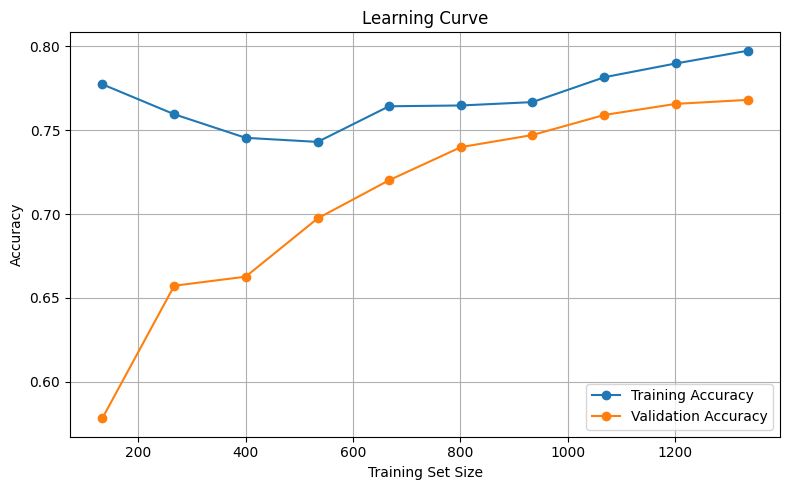

In [104]:
train_sizes = np.linspace(0.1, 1.0, 10)

train_sizes, train_scores, test_scores = learning_curve(
    poly_model, X_train, y_train,
    train_sizes=train_sizes,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores_mean, 'o-', label='Training Accuracy')
plt.plot(train_sizes, test_scores_mean, 'o-', label='Validation Accuracy')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [105]:
X1 = df.drop(columns=['BMI', 'weight', 'obesity_level'])

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y, test_size=0.2, random_state=42)

In [106]:
X2 = df.drop(columns=['BMI', 'obesity_level'])

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)

In [107]:
## without Weight and BMI
categorical = ['gender','snacking','alcohol_intake','transport_type']
numerical = ['age','height','veggies_freq','meal_count','water_intake','exercise_freq','screen_time','nutrition_score','family_history_overweight','high_caloric_food','smokes','calorie_monitoring','risk_factors']
target = ['obesity_level']

preprocessor1 = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('scaler', MinMaxScaler())
        ]), numerical),

        ('cat', Pipeline(steps=[
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical)
    ]
)

In [108]:
model1_pipeline = Pipeline([
    ('preprocessor', preprocessor1),
    ('logreg', LogisticRegression(max_iter=1000, multi_class='multinomial', solver='lbfgs'))
])


model1_pipeline.fit(X1_train, y1_train)
y1_pred = model1_pipeline.predict(X1_test)

print("without BMI and weight")
print("Test Accuracy:", accuracy_score(y1_test, y1_pred))
print("Classification Report:\n", classification_report(y1_test, y1_pred))
print("="*70)


without BMI and weight
Test Accuracy: 0.6339712918660287
Classification Report:
               precision    recall  f1-score   support

           0       0.66      0.68      0.67        59
           1       0.59      0.38      0.46        61
           2       0.51      0.67      0.58        70
           3       0.66      0.91      0.76        64
           4       0.97      1.00      0.98        60
           5       0.47      0.38      0.42        55
           6       0.52      0.33      0.40        49

    accuracy                           0.63       418
   macro avg       0.62      0.62      0.61       418
weighted avg       0.63      0.63      0.62       418



In [109]:
#Without BMI and with Weight
categorical = ['gender','snacking','alcohol_intake','transport_type']
numerical = ['age','weight','height','veggies_freq','meal_count','water_intake','exercise_freq','screen_time','nutrition_score','family_history_overweight','high_caloric_food','smokes','calorie_monitoring','risk_factors']
target = ['obesity_level']

preprocessor2 = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('scaler', MinMaxScaler())
        ]), numerical),

        ('cat', Pipeline(steps=[
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical)
    ]
)

In [110]:
model2_pipeline = Pipeline([
    ('preprocessor', preprocessor2),
    ('logreg', LogisticRegression(max_iter=1000, multi_class='multinomial', solver='lbfgs'))
])

model2_pipeline.fit(X2_train, y2_train)

y2_pred = model2_pipeline.predict(X2_test)

print("with weight without BMI")
print("Accuracy:", accuracy_score(y2_test, y2_pred))
print("Classification Report:\n", classification_report(y2_test, y2_pred))
print("="*70)


with weight without BMI
Accuracy: 0.7416267942583732
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.89      0.82        53
           1       0.64      0.51      0.57        57
           2       0.74      0.79      0.76        70
           3       0.74      0.98      0.84        60
           4       0.96      0.98      0.97        65
           5       0.67      0.65      0.66        55
           6       0.54      0.34      0.42        58

    accuracy                           0.74       418
   macro avg       0.72      0.74      0.72       418
weighted avg       0.73      0.74      0.73       418



## Model Selection (Comparison of Multiple Models)

In [111]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)
    ]
)

In [112]:
linear_models = {
    "SVM": Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', SVC())
    ])
}

In [113]:
tree_models = {
    "Random Forest": Pipeline([
        ('preprocessor', tree_preprocessor),
        ('classifier', RandomForestClassifier())
    ]),
    "Decision Tree": Pipeline([
        ('preprocessor', tree_preprocessor),
        ('classifier', DecisionTreeClassifier())
    ]),
    "LightGBM": Pipeline([
        ('preprocessor', tree_preprocessor),
        ('classifier', LGBMClassifier(verbosity=-1))
    ]),
    "XGBoost": Pipeline([
        ('preprocessor', tree_preprocessor),
        ('classifier', XGBClassifier(use_label_encoder=False, eval_metric='mlogloss',verbosity=0))
    ])
}

In [114]:
all_models = {**linear_models, **tree_models}
results = {}

In [115]:
for name, pipeline in all_models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

In [116]:
results

{'SVM': 0.8325358851674641,
 'Random Forest': 0.9473684210526315,
 'Decision Tree': 0.9114832535885168,
 'LightGBM': 0.9784688995215312,
 'XGBoost': 0.9736842105263158}

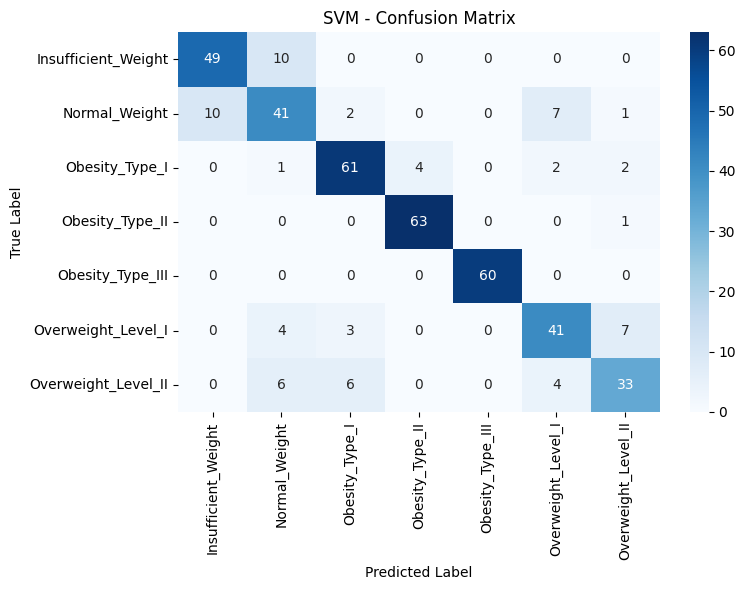

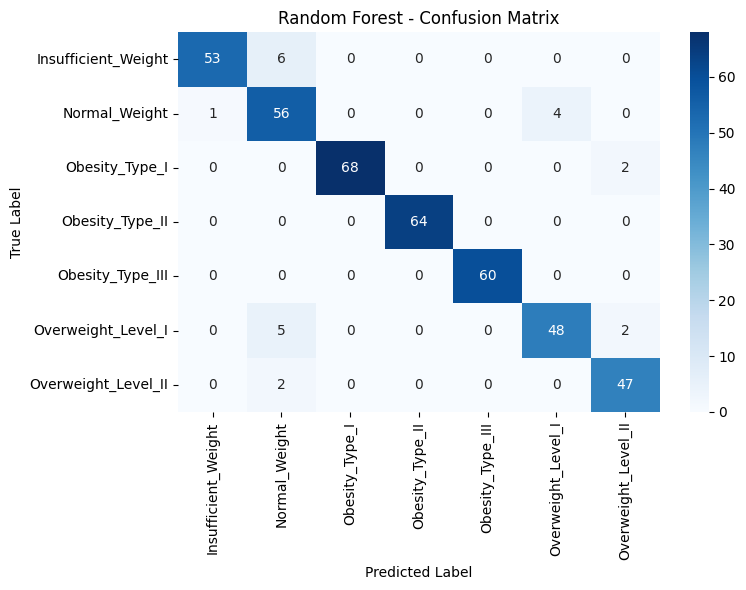

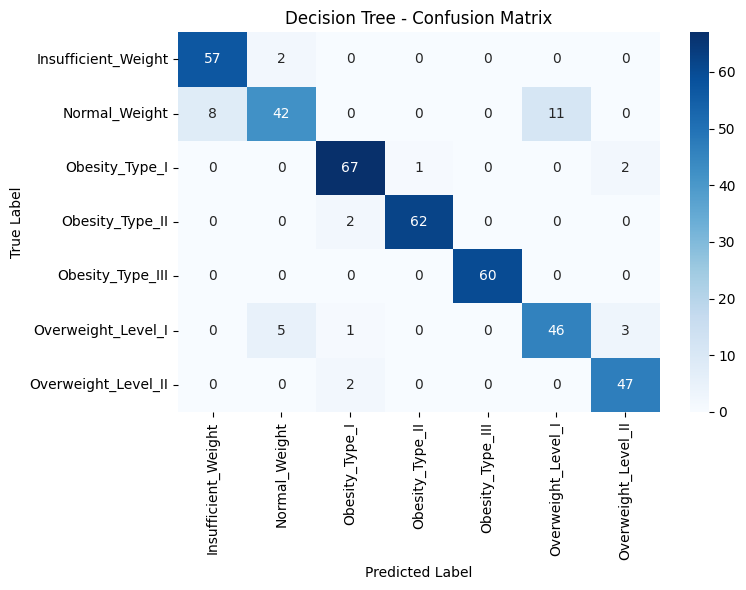

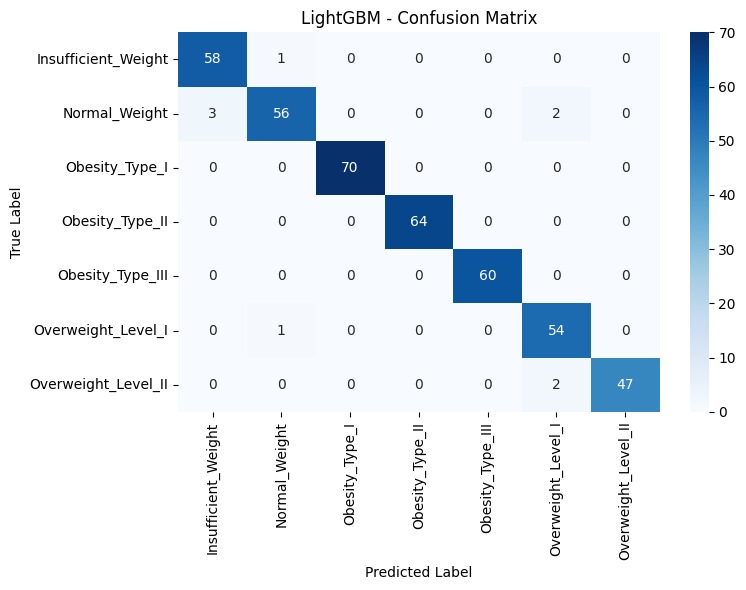

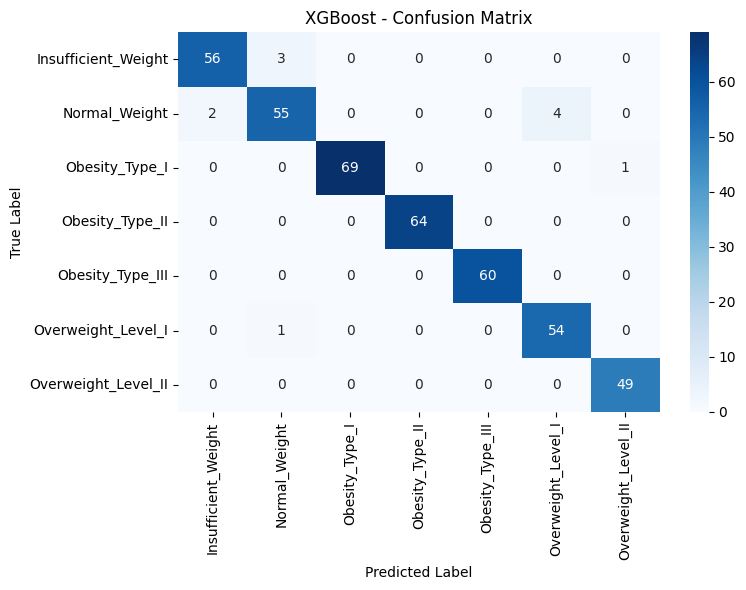

In [117]:
reports = {}
conf_matrices = {}

for name, model in all_models.items():
    y_pred = model.predict(X_test)
    report = classification_report(y_test, y_pred, target_names=label_encoder.classes_, output_dict=True)
    matrix = confusion_matrix(y_test, y_pred)

    reports[name] = report
    conf_matrices[name] = matrix

    plt.figure(figsize=(8, 6))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.classes_,
                yticklabels=label_encoder.classes_)
    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()


Generating learning curve for SVM...


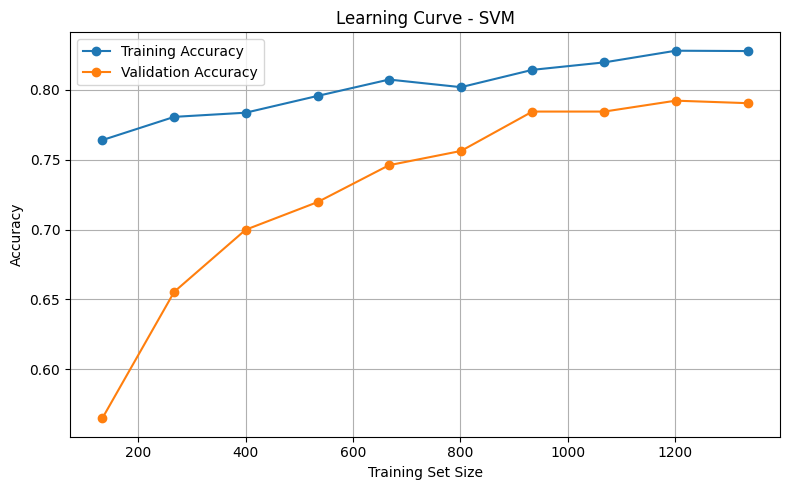

Generating learning curve for Random Forest...


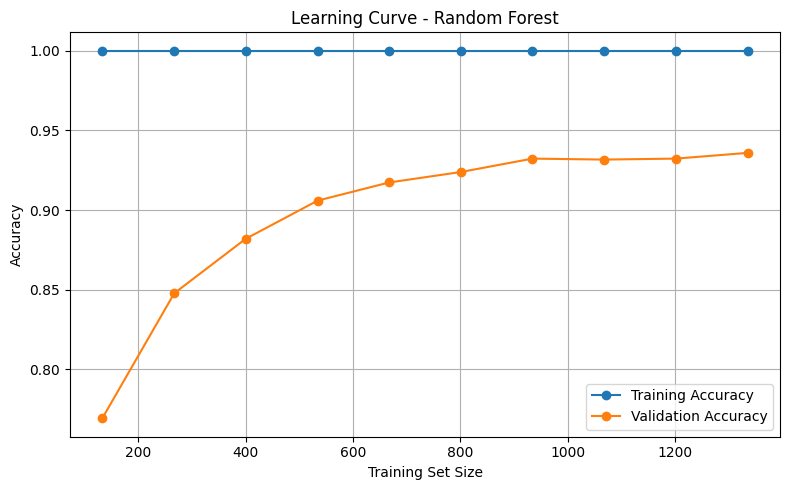

Generating learning curve for Decision Tree...


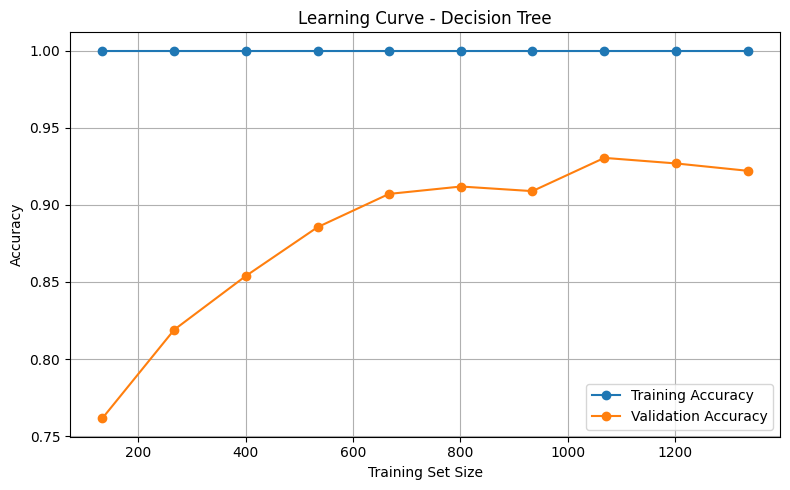

Generating learning curve for LightGBM...


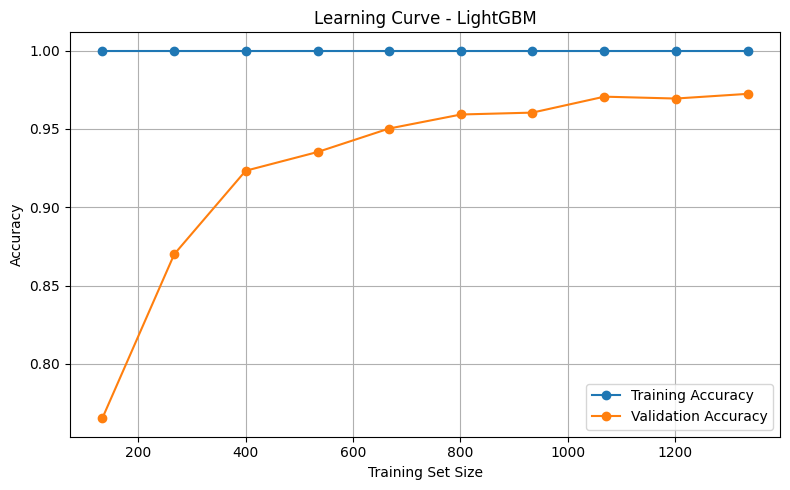

Generating learning curve for XGBoost...


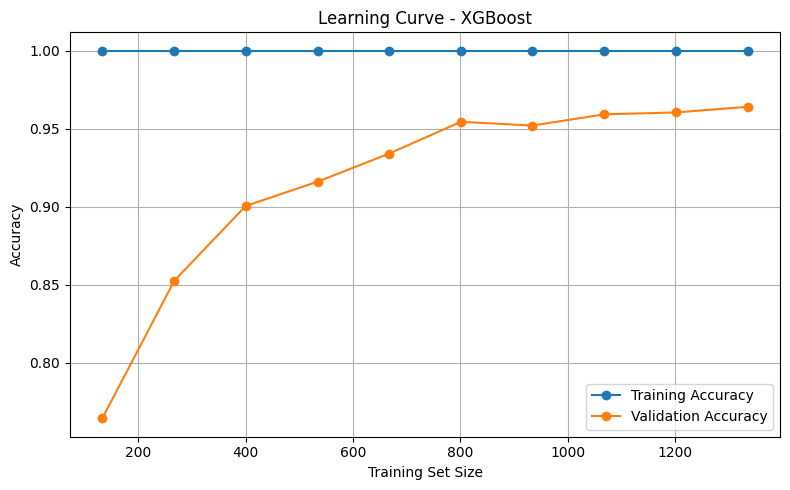

In [118]:
for name, model in all_models.items():
    print(f"Generating learning curve for {name}...")
    train_sizes, train_scores, test_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    train_mean = np.mean(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)

    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes, train_mean, 'o-', label='Training Accuracy')
    plt.plot(train_sizes, test_mean, 'o-', label='Validation Accuracy')
    plt.title(f'Learning Curve - {name}')
    plt.xlabel('Training Set Size')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


***note***

here we will take the SVM and LGBM because they are the least models to overfit

## Feature Impact Analysis: BMI and Weight

In [119]:
## Without BMI and Weight

categorical = ['gender', 'snacking', 'alcohol_intake', 'transport_type']
numerical = [
    'age', 'height', 'veggies_freq', 'meal_count', 'water_intake',
    'exercise_freq', 'screen_time', 'nutrition_score',
    'family_history_overweight', 'high_caloric_food',
    'smokes', 'calorie_monitoring', 'risk_factors'
]
target = ['obesity_level']


tree_preprocessor1 = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)
    ]
)

In [120]:
## Without BMI and with weight

categorical = ['gender', 'snacking', 'alcohol_intake', 'transport_type']
numerical = [
    'age', 'weight' ,'height', 'veggies_freq', 'meal_count', 'water_intake',
    'exercise_freq', 'screen_time', 'nutrition_score',
    'family_history_overweight', 'high_caloric_food',
    'smokes', 'calorie_monitoring', 'risk_factors'
]
target = ['obesity_level']


tree_preprocessor2 = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)
    ]
)

 <p align="center">SVM</p>


In [121]:
svm_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor1),
    ('svm', SVC())
])

svm_pipeline.fit(X1_train, y1_train)


y2_pred = svm_pipeline.predict(X1_test)


print("SVM - without BMI and weight")
print("Accuracy:", accuracy_score(y1_test, y1_pred))
print("Classification Report:\n", classification_report(y1_test, y1_pred))
print("="*70)


SVM - without BMI and weight
Accuracy: 0.6339712918660287
Classification Report:
               precision    recall  f1-score   support

           0       0.66      0.68      0.67        59
           1       0.59      0.38      0.46        61
           2       0.51      0.67      0.58        70
           3       0.66      0.91      0.76        64
           4       0.97      1.00      0.98        60
           5       0.47      0.38      0.42        55
           6       0.52      0.33      0.40        49

    accuracy                           0.63       418
   macro avg       0.62      0.62      0.61       418
weighted avg       0.63      0.63      0.62       418



In [122]:
svm_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor2),
    ('svm', SVC())
])

svm_pipeline.fit(X2_train, y2_train)


y2_pred = svm_pipeline.predict(X2_test)


print("SVM - without BMI and with weight")
print("Accuracy:", accuracy_score(y2_test, y2_pred))
print("Classification Report:\n", classification_report(y2_test, y2_pred))
print("="*70)


SVM - without BMI and with weight
Accuracy: 0.5311004784688995
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.85      0.80        53
           1       0.51      0.37      0.43        57
           2       0.37      0.36      0.36        70
           3       0.66      0.68      0.67        60
           4       0.60      0.51      0.55        65
           5       0.45      0.42      0.43        55
           6       0.42      0.59      0.49        58

    accuracy                           0.53       418
   macro avg       0.54      0.54      0.53       418
weighted avg       0.53      0.53      0.53       418



<p align="center">Decision Tree</p>


In [123]:
tree1_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor1),
    ('tree', DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42))
])

tree1_pipeline.fit(X1_train, y1_train)

y1_pred = tree1_pipeline.predict(X1_test)

print("Decision Tree - without weight and BMI")
print("Accuracy:", accuracy_score(y1_test, y1_pred))
print("Classification Report:\n", classification_report(y1_test, y1_pred))
print("="*70)

Decision Tree - without weight and BMI
Accuracy: 0.645933014354067
Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.66      0.70        59
           1       0.50      0.54      0.52        61
           2       0.47      0.86      0.61        70
           3       0.81      0.80      0.80        64
           4       1.00      0.95      0.97        60
           5       0.61      0.25      0.36        55
           6       0.57      0.33      0.42        49

    accuracy                           0.65       418
   macro avg       0.67      0.63      0.62       418
weighted avg       0.67      0.65      0.63       418



In [124]:
tree2_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor2),
    ('tree', DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42))
])


tree2_pipeline.fit(X2_train, y2_train)


y2_pred = tree2_pipeline.predict(X2_test)


print("Decision Tree - with weight without BMI")
print("Accuracy:", accuracy_score(y2_test, y2_pred))
print("Classification Report:\n", classification_report(y2_test, y2_pred))
print("="*70)


Decision Tree - with weight without BMI
Accuracy: 0.8181818181818182
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.98      0.91        53
           1       0.91      0.56      0.70        57
           2       0.77      0.96      0.85        70
           3       0.98      0.98      0.98        60
           4       1.00      0.98      0.99        65
           5       0.70      0.51      0.59        55
           6       0.56      0.69      0.62        58

    accuracy                           0.82       418
   macro avg       0.83      0.81      0.81       418
weighted avg       0.83      0.82      0.81       418



 <p align="center">Random Forest</p>


In [125]:
rf1_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor1),
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])

rf1_pipeline.fit(X1_train, y1_train)

y1_pred = rf1_pipeline.predict(X1_test)

print("Random Forest - Without BMI and weight")  
print("Accuracy:", accuracy_score(y1_test, y1_pred))
print("Classification Report:\n", classification_report(y1_test, y1_pred))
print("="*70)


Random Forest - Without BMI and weight
Accuracy: 0.7200956937799043
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.75      0.77        59
           1       0.57      0.51      0.54        61
           2       0.57      0.86      0.69        70
           3       0.76      0.97      0.85        64
           4       0.94      1.00      0.97        60
           5       0.77      0.42      0.54        55
           6       0.75      0.43      0.55        49

    accuracy                           0.72       418
   macro avg       0.74      0.70      0.70       418
weighted avg       0.73      0.72      0.71       418



In [126]:
rf_pipeline2 = Pipeline([
    ('preprocessor', tree_preprocessor2),
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])

rf_pipeline2.fit(X2_train, y2_train)

y2_pred_rf = rf_pipeline2.predict(X2_test)

print("Random Forest - with weight and without BMI")
print("Accuracy:", accuracy_score(y2_test, y2_pred_rf))
print("Classification Report:\n", classification_report(y1_test, y2_pred_rf))
print("="*70)


Random Forest - with weight and without BMI
Accuracy: 0.8277511961722488
Classification Report:
               precision    recall  f1-score   support

           0       0.12      0.12      0.12        59
           1       0.12      0.11      0.12        61
           2       0.08      0.09      0.08        70
           3       0.16      0.17      0.17        64
           4       0.17      0.18      0.18        60
           5       0.14      0.11      0.12        55
           6       0.11      0.12      0.12        49

    accuracy                           0.13       418
   macro avg       0.13      0.13      0.13       418
weighted avg       0.13      0.13      0.13       418



<p align="center">LGBM</p>


In [127]:
lgbm1_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor1),
    ('lgbm', LGBMClassifier(max_depth=5, n_estimators=100, random_state=42, verbosity=-1)) 
])

lgbm1_pipeline.fit(X1_train, y1_train)

y1_pred = lgbm1_pipeline.predict(X1_test)

print("LGBM - Without BMI and weight")
print("Accuracy:", accuracy_score(y1_test, y1_pred))
print("Classification Report:\n", classification_report(y1_test, y1_pred))
print("="*70)


LGBM - Without BMI and weight
Accuracy: 0.8516746411483254
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.85      0.91        59
           1       0.67      0.69      0.68        61
           2       0.79      0.90      0.84        70
           3       0.97      0.94      0.95        64
           4       1.00      1.00      1.00        60
           5       0.89      0.75      0.81        55
           6       0.71      0.82      0.76        49

    accuracy                           0.85       418
   macro avg       0.86      0.85      0.85       418
weighted avg       0.86      0.85      0.85       418



In [128]:
df.head()

,gender,age,height,weight,family_history_overweight,high_caloric_food,veggies_freq,meal_count,snacking,smokes,water_intake,calorie_monitoring,exercise_freq,screen_time,alcohol_intake,transport_type,BMI,risk_factors,nutrition_score,obesity_level
0,Female,21.0,1.62,64.0,1,0,2.0,3.0,Sometimes,0,2.0,0,0.0,1.0,no,Public_Transportation,24.39,2,0.56,1
1,Female,21.0,1.52,56.0,1,0,3.0,3.0,Sometimes,1,3.0,1,3.0,0.0,Sometimes,Public_Transportation,24.24,1,0.89,1
2,Male,23.0,1.80,77.0,1,0,2.0,3.0,Sometimes,0,2.0,0,2.0,1.0,Frequently,Public_Transportation,23.77,1,0.56,1
3,Male,27.0,1.80,87.0,0,0,3.0,3.0,Sometimes,0,2.0,0,2.0,0.0,Frequently,Walking,26.85,1,0.72,5
4,Male,22.0,1.78,89.8,0,0,2.0,1.0,Sometimes,0,2.0,0,0.0,0.0,Sometimes,Public_Transportation,28.34,2,0.33,6


## Model Fine-Tuning (Hyperparameter Tuning)

<p align="center">LGBM & SVM Hyperparameter Tuning</p>


In [129]:
lgbm_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('lgbm', LGBMClassifier(random_state=42, verbosity=-1))
])

lgbm_param_dist = {
    'lgbm__n_estimators': [100, 150, 200],
    'lgbm__max_depth': [3, 7, 10],
    'lgbm__learning_rate': [ 0.05, 0.1, 0.2],
    'lgbm__num_leaves': [15, 31, 63],
    'lgbm__min_child_samples': [20, 30]
}

lgbm_search = RandomizedSearchCV(
    estimator=lgbm_pipeline,
    param_distributions=lgbm_param_dist,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    n_jobs=2,
    random_state=42
)

lgbm_search.fit(X_train, y_train)

print("Best LGBM Parameters:", lgbm_search.best_params_)
print("Best LGBM Accuracy:", lgbm_search.best_score_)


Best LGBM Parameters: {'lgbm__num_leaves': 31, 'lgbm__n_estimators': 150, 'lgbm__min_child_samples': 20, 'lgbm__max_depth': 10, 'lgbm__learning_rate': 0.1}
Best LGBM Accuracy: 0.964648747788125


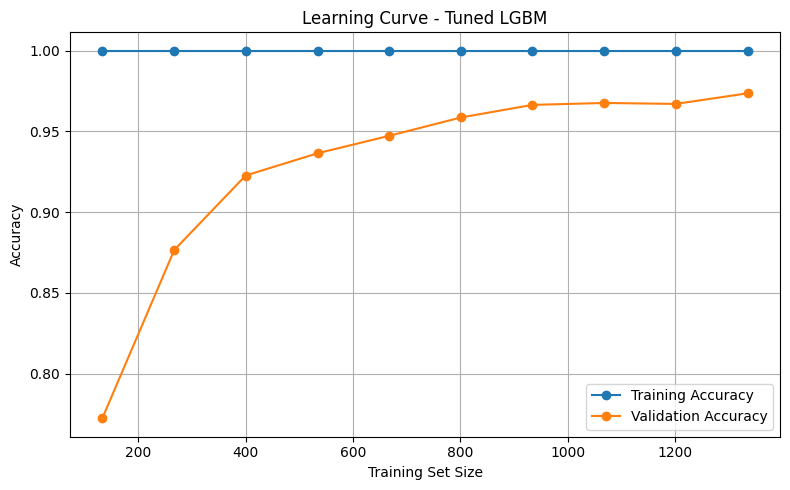

In [130]:
train_sizes, train_scores, test_scores = learning_curve(
    lgbm_search.best_estimator_, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, 'o-', label='Training Accuracy')
plt.plot(train_sizes, test_mean, 'o-', label='Validation Accuracy')
plt.title('Learning Curve - Tuned LGBM')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


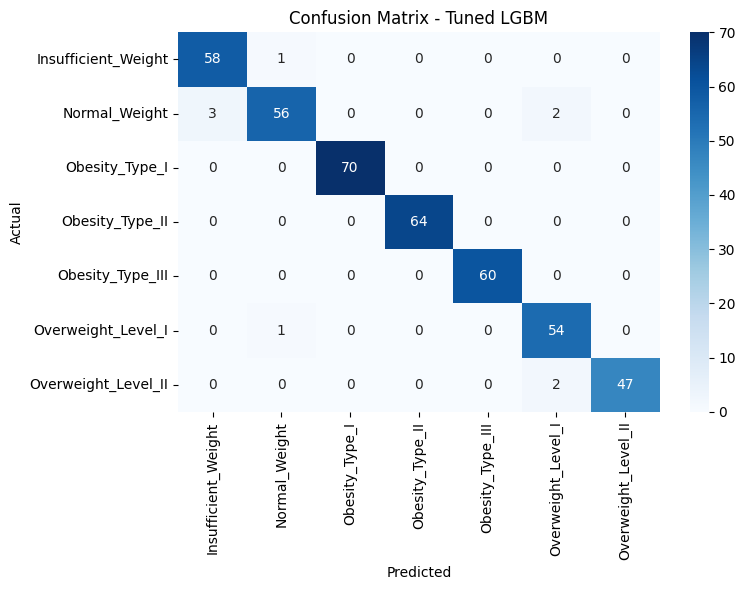

In [131]:
lgbm_best = lgbm_search.best_estimator_
y_pred_lgbm = lgbm_best.predict(X_test)


cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lgbm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix - Tuned LGBM')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


The LGBM model reached perfect training accuracy (1.0) showing it easily memorizes training data which led to a visible gap with validation accuracy especially on smaller datasets(like our case).
While validation accuracy improved steadily to ~0.95 as more data was used the model still showed moderate overfitting but it performed very well overall and generalized well when enough training data was available.

In [132]:
svm_pipeline = Pipeline([
    ('preprocessor', preprocessor),  
    ('svm', SVC(probability=True))
])

svm_param_dist = {
    'svm__C': np.logspace(-2, 2, 10), 
    'svm__kernel': ['linear', 'rbf'],
    'svm__gamma': ['scale', 'auto']
}

svm_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_param_dist,
    n_iter=15,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

svm_search.fit(X_train, y_train)

print("Best SVM Parameters:", svm_search.best_params_)
print("Best SVM Accuracy:", svm_search.best_score_)


Best SVM Parameters: {'svm__kernel': 'linear', 'svm__gamma': 'auto', 'svm__C': 35.93813663804626}
Best SVM Accuracy: 0.9556634478790167


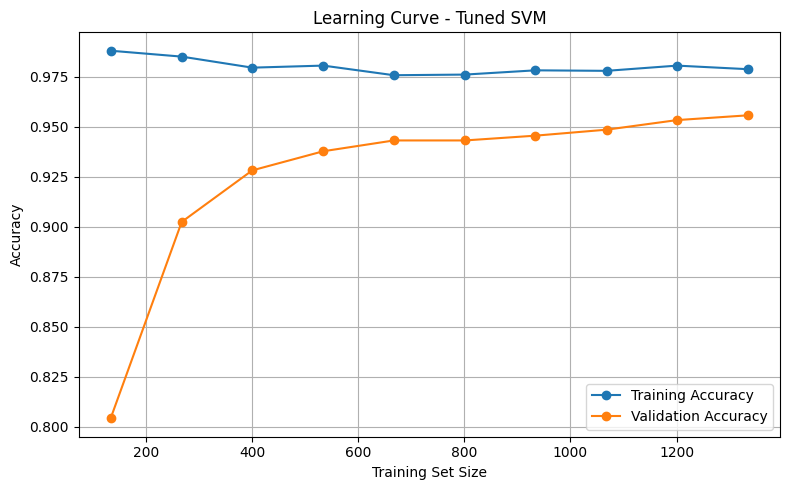

In [133]:
train_sizes, train_scores, test_scores = learning_curve(
    svm_search.best_estimator_, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, 'o-', label='Training Accuracy')
plt.plot(train_sizes, test_mean, 'o-', label='Validation Accuracy')
plt.title('Learning Curve - Tuned SVM')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


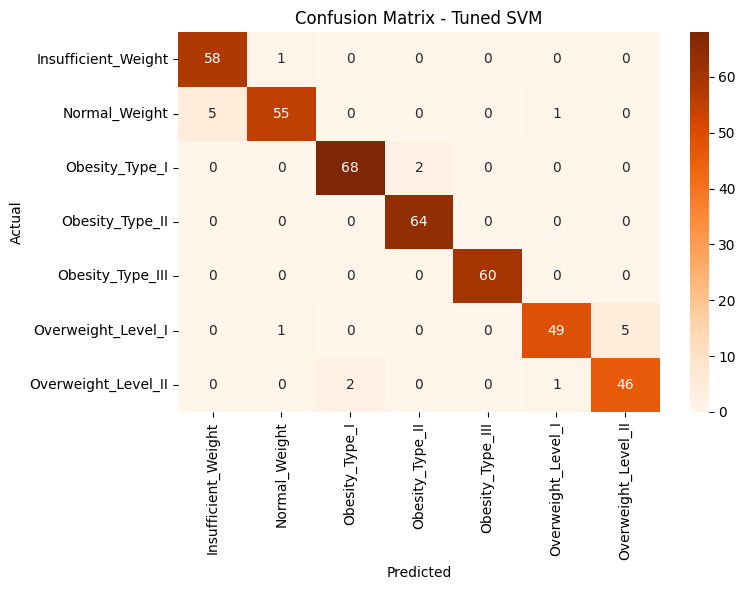

In [134]:
svm_best = svm_search.best_estimator_
y_pred_svm = svm_best.predict(X_test)


cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix - Tuned SVM')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


The SVM model maintained high but slightly lower training accuracy (~0.96–0.98) and had validation accuracy that consistently tracked close to it reaching ~0.95
This close alignment between the curves indicates excellent generalization with minimal overfitting 

SVM proved to be the most stable and balanced model across training sizes


<p align="center">LGBM Parameter Changing(multiple tries in order to reduce over fitting)</p>


In [135]:
lgbm2_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor2),
    ('lgbm', LGBMClassifier(
        max_depth=3,               
        num_leaves=7,             
        min_child_samples=30,      
        reg_alpha=1.0,             
        reg_lambda=1.0,           
        subsample=0.8,             
        colsample_bytree=0.8,
        learning_rate=0.05,
        n_estimators=1000,
        random_state=42,
        verbosity=-1
    ))
])

lgbm2_pipeline.fit(X2_train, y2_train)


y2_pred = lgbm2_pipeline.predict(X2_test)


print("LGBM - with weight without BMI")
print("Accuracy:", accuracy_score(y2_test, y2_pred))
print("Classification Report:\n", classification_report(y2_test, y2_pred))
print("="*70)
train_preds = lgbm2_pipeline.predict(X2_train)
print("Train Accuracy:", accuracy_score(y2_train, train_preds))


LGBM - with weight without BMI
Accuracy: 0.9688995215311005
Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        53
           1       0.95      0.96      0.96        57
           2       1.00      0.96      0.98        70
           3       0.98      1.00      0.99        60
           4       1.00      0.98      0.99        65
           5       0.94      0.91      0.93        55
           6       0.92      0.97      0.94        58

    accuracy                           0.97       418
   macro avg       0.97      0.97      0.97       418
weighted avg       0.97      0.97      0.97       418

Train Accuracy: 0.9994008388256441


In [136]:
from sklearn.model_selection import GridSearchCV
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('preprocessor', tree_preprocessor2),
    ('lgbm', LGBMClassifier(random_state=42, verbosity=-1))
])

param_grid = {
    'lgbm__max_depth': [3, 5, 7],
    'lgbm__num_leaves': [7, 15, 31],
    'lgbm__learning_rate': [0.01, 0.05, 0.1],
    'lgbm__n_estimators': [100, 300, 500],
    'lgbm__min_child_samples': [10, 20, 30],
    'lgbm__reg_alpha': [0.0, 1.0],
    'lgbm__reg_lambda': [0.0, 1.0]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    cv=3,  
    scoring='accuracy',
    n_jobs=-1,  
    verbose=2
)

grid_search.fit(X2_train, y2_train)

print("أفضل دقة (CV accuracy):", grid_search.best_score_)
print("أفضل إعدادات (Best Params):")
print(grid_search.best_params_)

best_model = grid_search.best_estimator_
y2_pred = best_model.predict(X2_test)

print("\n== تقييم على بيانات الاختبار ==")
print("Test Accuracy:", accuracy_score(y2_test, y2_pred))
print("Classification Report:\n", classification_report(y2_test, y2_pred))

train_preds = best_model.predict(X2_train)
train_accuracy = accuracy_score(y2_train, train_preds)

print("Train Accuracy:", train_accuracy)



Fitting 3 folds for each of 972 candidates, totalling 2916 fits
أفضل دقة (CV accuracy): 0.9706407226104217
أفضل إعدادات (Best Params):
{'lgbm__learning_rate': 0.05, 'lgbm__max_depth': 5, 'lgbm__min_child_samples': 10, 'lgbm__n_estimators': 500, 'lgbm__num_leaves': 15, 'lgbm__reg_alpha': 0.0, 'lgbm__reg_lambda': 0.0}

== تقييم على بيانات الاختبار ==
Test Accuracy: 0.9856459330143541
Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        53
           1       0.98      0.98      0.98        57
           2       1.00      0.99      0.99        70
           3       0.98      1.00      0.99        60
           4       1.00      0.98      0.99        65
           5       0.98      0.95      0.96        55
           6       0.97      1.00      0.98        58

    accuracy                           0.99       418
   macro avg       0.99      0.99      0.99       418
weighted avg       0.99      0.99      0.99      

In [137]:
from sklearn.pipeline import Pipeline
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report

optimized_lgbm_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor2),
    ('lgbm', LGBMClassifier(
        learning_rate=0.05,
        max_depth=5,
        num_leaves=15,
        min_child_samples=20,   
        n_estimators=400,        
        reg_alpha=0.5,           
        reg_lambda=0.5,          
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbosity=-1
    ))
])

optimized_lgbm_pipeline.fit(X2_train, y2_train)

y2_pred = optimized_lgbm_pipeline.predict(X2_test)
print("LGBM - بعد تحسينات تقليل الأوفر فيت")
print("Test Accuracy:", accuracy_score(y2_test, y2_pred))
print("Classification Report:\n", classification_report(y2_test, y2_pred))
print("="*70)

train_preds = optimized_lgbm_pipeline.predict(X2_train)
print("Train Accuracy:", accuracy_score(y2_train, train_preds))


LGBM - بعد تحسينات تقليل الأوفر فيت
Test Accuracy: 0.9665071770334929
Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        53
           1       0.95      0.96      0.96        57
           2       1.00      0.94      0.97        70
           3       0.97      1.00      0.98        60
           4       1.00      0.98      0.99        65
           5       0.94      0.91      0.93        55
           6       0.92      0.97      0.94        58

    accuracy                           0.97       418
   macro avg       0.97      0.97      0.97       418
weighted avg       0.97      0.97      0.97       418

Train Accuracy: 1.0


In [138]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from lightgbm import LGBMClassifier
from lightgbm import early_stopping, log_evaluation


X_train_final, X_valid, y_train_final, y_valid = train_test_split(X2_train, y2_train, test_size=0.2, random_state=42)

tree_preprocessor2.fit(X_train_final)
X_train_proc = tree_preprocessor2.transform(X_train_final)
X_valid_proc = tree_preprocessor2.transform(X_valid)
X_test_proc = tree_preprocessor2.transform(X2_test)
X_full_train_proc = tree_preprocessor2.transform(X2_train)

lgbm = LGBMClassifier(
    learning_rate=0.05,
    max_depth=5,
    num_leaves=15,
    min_child_samples=20,
    n_estimators=1000,
    reg_alpha=0.5,
    reg_lambda=0.5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

lgbm.fit(
    X_train_proc,
    y_train_final,
    eval_set=[(X_valid_proc, y_valid)],
    eval_metric='multi_logloss',
    callbacks=[early_stopping(30), log_evaluation(100)]
)

y2_pred = lgbm.predict(X_test_proc)
print("Early Stopping")
print("Test Accuracy:", accuracy_score(y2_test, y2_pred))
print("Classification Report:\n", classification_report(y2_test, y2_pred))
print("="*70)

train_preds = lgbm.predict(X_full_train_proc)
print("Train Accuracy:", accuracy_score(y2_train, train_preds))


Training until validation scores don't improve for 30 rounds
[100]	valid_0's multi_logloss: 0.113755
[200]	valid_0's multi_logloss: 0.0845267
Early stopping, best iteration is:
[219]	valid_0's multi_logloss: 0.0840779
Early Stopping
Test Accuracy: 0.9569377990430622
Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        53
           1       0.92      0.96      0.94        57
           2       1.00      0.94      0.97        70
           3       0.95      1.00      0.98        60
           4       1.00      0.98      0.99        65
           5       0.94      0.85      0.90        55
           6       0.90      0.95      0.92        58

    accuracy                           0.96       418
   macro avg       0.96      0.96      0.96       418
weighted avg       0.96      0.96      0.96       418

Train Accuracy: 0.9952067106051528



<p align="center">Automated feature selection for LGBM</p>


In [139]:
categorical = ['gender','snacking','alcohol_intake','transport_type']
numerical = ['age','height','weight','veggies_freq','meal_count','water_intake',
             'exercise_freq','screen_time','BMI','nutrition_score',
             'family_history_overweight','high_caloric_food','smokes',
             'calorie_monitoring','risk_factors']

preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('num', 'passthrough', numerical)
])

X_processed = preprocessor.fit_transform(X)

model = LGBMClassifier()
model.fit(X_processed, y)

selector = SelectFromModel(model, prefit=True, threshold="median")
X_selected = selector.transform(X_processed)

print("Original shape:", X_processed.shape)
print("Selected shape:", X_selected.shape)


Original shape: (2087, 30)
Selected shape: (2087, 15)


In [140]:
ohe = preprocessor.named_transformers_['cat']
cat_features = ohe.get_feature_names_out(categorical)
all_features = list(cat_features) + numerical

selected_features = [f for f, s in zip(all_features, selector.get_support()) if s]

print("Selected features:")
for name in selected_features:
    print("-", name)


Selected features:
- gender_Female
- transport_type_Automobile
- age
- height
- weight
- veggies_freq
- meal_count
- water_intake
- exercise_freq
- screen_time
- BMI
- nutrition_score
- family_history_overweight
- high_caloric_food
- risk_factors


In [141]:
tree_preprocessor2.fit(X2_train)

X_train_proc_all = tree_preprocessor2.transform(X2_train)
X_test_proc_all = tree_preprocessor2.transform(X2_test)

base_lgbm = LGBMClassifier(random_state=42)
base_lgbm.fit(X_train_proc_all, y2_train)

selector = SelectFromModel(base_lgbm, prefit=True, threshold="median")

X_train_selected = selector.transform(X_train_proc_all)
X_test_selected = selector.transform(X_test_proc_all)

X_train_final, X_valid, y_train_final, y_valid = train_test_split(
    X_train_selected, y2_train, test_size=0.2, random_state=42
)

lgbm = LGBMClassifier(
    learning_rate=0.05,
    max_depth=5,
    num_leaves=15,
    min_child_samples=20,
    n_estimators=1000,
    reg_alpha=0.5,
    reg_lambda=0.5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

lgbm.fit(
    X_train_final,
    y_train_final,
    eval_set=[(X_valid, y_valid)],
    eval_metric='multi_logloss',
    callbacks=[early_stopping(30), log_evaluation(100)]
)

y2_pred = lgbm.predict(X_test_selected)
print("Early Stopping")
print("Test Accuracy:", accuracy_score(y2_test, y2_pred))
print("Classification Report:\n", classification_report(y2_test, y2_pred))

train_preds = lgbm.predict(X_train_selected)
print("Train Accuracy:", accuracy_score(y2_train, train_preds))

Training until validation scores don't improve for 30 rounds
[100]	valid_0's multi_logloss: 0.113119
[200]	valid_0's multi_logloss: 0.0800931
[300]	valid_0's multi_logloss: 0.0797462
[400]	valid_0's multi_logloss: 0.0797358
Early stopping, best iteration is:
[371]	valid_0's multi_logloss: 0.0797211
Early Stopping
Test Accuracy: 0.9617224880382775
Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        53
           1       0.90      0.95      0.92        57
           2       1.00      0.94      0.97        70
           3       0.95      1.00      0.98        60
           4       1.00      0.98      0.99        65
           5       0.94      0.87      0.91        55
           6       0.95      0.98      0.97        58

    accuracy                           0.96       418
   macro avg       0.96      0.96      0.96       418
weighted avg       0.96      0.96      0.96       418

Train Accuracy: 0.995805871779

<p align="center">Ensembling LGBM & SVM</p>


In [142]:
lgbm_best = lgbm_search.best_estimator_
svm_best = svm_search.best_estimator_


ensemble_model = VotingClassifier(
    estimators=[('lgbm', lgbm_best), ('svm', svm_best)],
    voting='soft'  
)

In [143]:

lgbm_best.fit(X_train, y_train)
svm_best.fit(X_train, y_train)
ensemble_model.fit(X_train, y_train)

y_pred_lgbm = lgbm_best.predict(X_test)
y_pred_svm = svm_best.predict(X_test)
y_pred_ensemble = ensemble_model.predict(X_test)


acc_lgbm = accuracy_score(y_test, y_pred_lgbm)
acc_svm = accuracy_score(y_test, y_pred_svm)
acc_ensemble = accuracy_score(y_test, y_pred_ensemble)


print("Accuracy Scores:")
print(f"LGBM Accuracy:      {acc_lgbm:.4f}")
print(f"SVM Accuracy:       {acc_svm:.4f}")
print(f"Ensemble Accuracy:  {acc_ensemble:.4f}")


Accuracy Scores:
LGBM Accuracy:      0.9785
SVM Accuracy:       0.9569
Ensemble Accuracy:  0.9856


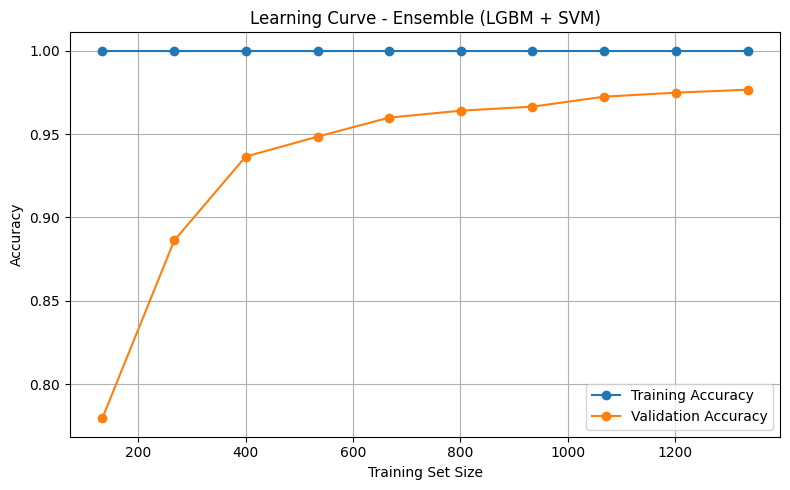

In [144]:
train_sizes, train_scores, test_scores = learning_curve(
    ensemble_model, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, 'o-', label='Training Accuracy')
plt.plot(train_sizes, test_mean, 'o-', label='Validation Accuracy')
plt.title('Learning Curve - Ensemble (LGBM + SVM)')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


The ensemble model inherited LGBM’s perfect training accuracy (1.0) and achieved the highest validation accuracy (~0.96)

It combined the strengths of both models but also showed mild overfitting and minor instability with fluctuations around mid-range training sizes

it delivered the best performance in terms of accuracy but was slightly less stable than SVM


<p align="center">Cross Validation for LGBM & SVM</p>


In [145]:
lgbm_cv_scores = cross_val_score(lgbm_best, X, y, cv=5, scoring='accuracy')
print("LGBM CV Accuracy: ", lgbm_cv_scores)
print("Mean:", np.mean(lgbm_cv_scores), "Std:", np.std(lgbm_cv_scores))


LGBM CV Accuracy:  [0.784689   0.98564593 0.99280576 0.98800959 0.98561151]
Mean: 0.9473523573485709 Std: 0.08137389297554465


In [146]:
svm_cv_scores = cross_val_score(svm_best, X, y, cv=5, scoring='accuracy')
print("SVM CV Accuracy: ", svm_cv_scores)
print("Mean:", np.mean(svm_cv_scores), "Std:", np.std(svm_cv_scores))


SVM CV Accuracy:  [0.84449761 0.97129187 0.97122302 0.97601918 0.98321343]
Mean: 0.9492490218351636 Std: 0.05255820584158064


In [147]:
ensemble_model = VotingClassifier(
    estimators=[('lgbm', lgbm_best), ('svm', svm_best)],
    voting='soft'
)

ensemble_cv_scores = cross_val_score(ensemble_model, X, y, cv=5, scoring='accuracy')
print("Ensemble CV Accuracy: ", ensemble_cv_scores)
print("Mean:", np.mean(ensemble_cv_scores), "Std:", np.std(ensemble_cv_scores))


Ensemble CV Accuracy:  [0.82057416 0.98564593 0.99520384 0.99280576 0.98561151]
Mean: 0.9559682397622572 Std: 0.06780483721147122


In [148]:
def plot_learning_curve(model, X, y, title):
    train_sizes, train_scores, test_scores = learning_curve(
        model, X, y,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    train_mean = np.mean(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)

    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes, train_mean, 'o-', label='Training Accuracy')
    plt.plot(train_sizes, test_mean, 'o-', label='Validation Accuracy')
    plt.title(title)
    plt.xlabel('Training Set Size')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


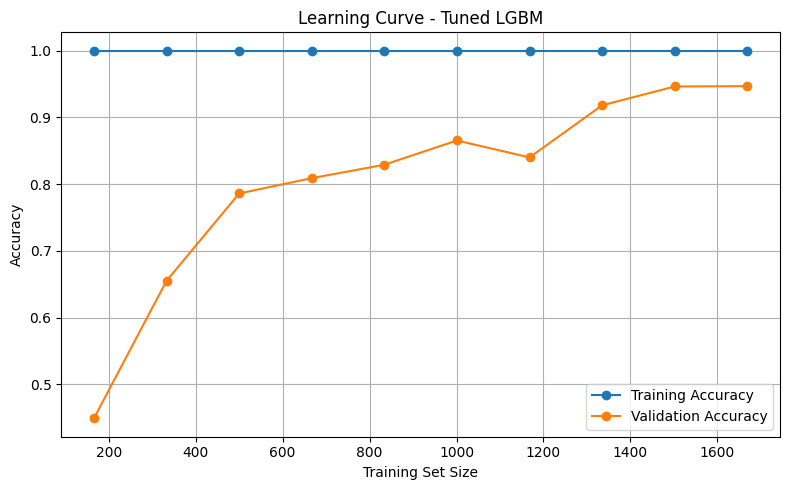

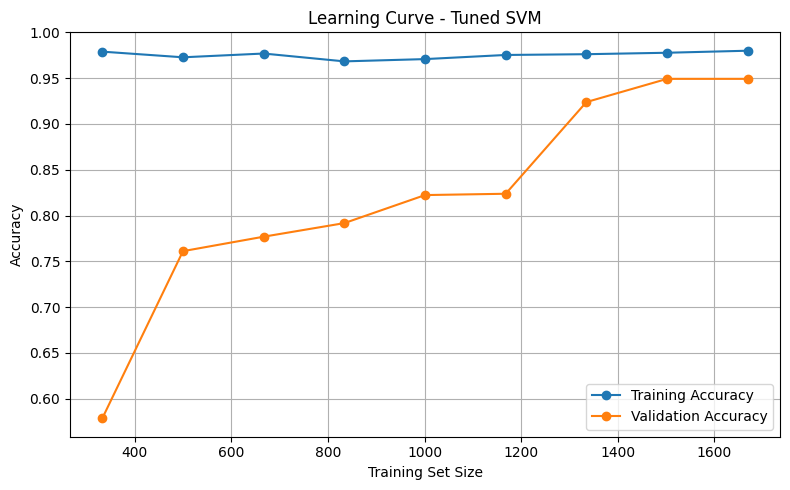

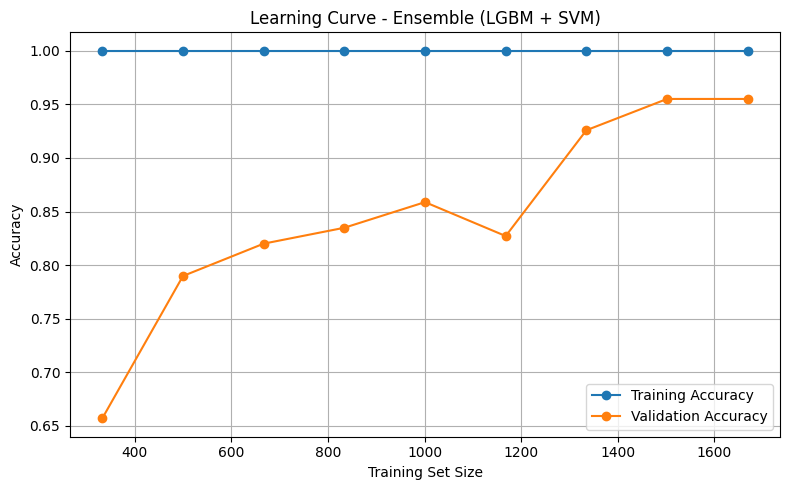

In [149]:
plot_learning_curve(lgbm_best, X, y, 'Learning Curve - Tuned LGBM')
plot_learning_curve(svm_best, X, y, 'Learning Curve - Tuned SVM')
plot_learning_curve(ensemble_model, X, y, 'Learning Curve - Ensemble (LGBM + SVM)')


The SVM model showed the best balance with low overfitting and strong generalization.
LGBM performed very well but tended to overfit especially on smaller data.
The ensemble gave the highest accuracy overall though it inherited some overfitting from LGBM.

## Final Model Evaluation

In [153]:
X_train_final, X_valid, y_train_final, y_valid = train_test_split(X2_train, y2_train, test_size=0.2, random_state=42)

tree_preprocessor2.fit(X_train_final)
X_train_proc = tree_preprocessor2.transform(X_train_final)
X_valid_proc = tree_preprocessor2.transform(X_valid)
X_test_proc = tree_preprocessor2.transform(X2_test)
X_full_train_proc = tree_preprocessor2.transform(X2_train)

lgbm = LGBMClassifier(
    learning_rate=0.05,
    max_depth=5,
    num_leaves=15,
    min_child_samples=20,
    n_estimators=1000,
    reg_alpha=0.5,
    reg_lambda=0.5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

lgbm.fit(
    X_train_proc,
    y_train_final,
    eval_set=[(X_valid_proc, y_valid)],
    eval_metric='multi_logloss',
    callbacks=[early_stopping(30), log_evaluation(100)]
)

y2_pred = lgbm.predict(X_test_proc)
print("Early Stopping")
print("Test Accuracy:", accuracy_score(y2_test, y2_pred))
print("Classification Report:\n", classification_report(y2_test, y2_pred))
print("="*70)

train_preds = lgbm.predict(X_full_train_proc)
print("Train Accuracy:", accuracy_score(y2_train, train_preds))


Training until validation scores don't improve for 30 rounds
[100]	valid_0's multi_logloss: 0.113755
[200]	valid_0's multi_logloss: 0.0845267
Early stopping, best iteration is:
[219]	valid_0's multi_logloss: 0.0840779
Early Stopping
Test Accuracy: 0.9569377990430622
Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        53
           1       0.92      0.96      0.94        57
           2       1.00      0.94      0.97        70
           3       0.95      1.00      0.98        60
           4       1.00      0.98      0.99        65
           5       0.94      0.85      0.90        55
           6       0.90      0.95      0.92        58

    accuracy                           0.96       418
   macro avg       0.96      0.96      0.96       418
weighted avg       0.96      0.96      0.96       418

Train Accuracy: 0.9952067106051528


In [154]:
train_acc = accuracy_score(y2_train, train_preds)
test_acc = accuracy_score(y2_test, y2_pred)

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print("\nClassification Report:\n")
print(classification_report(y2_test, y2_pred))

Train Accuracy: 0.9952
Test Accuracy: 0.9569

Classification Report:

              precision    recall  f1-score   support

           0       0.98      1.00      0.99        53
           1       0.92      0.96      0.94        57
           2       1.00      0.94      0.97        70
           3       0.95      1.00      0.98        60
           4       1.00      0.98      0.99        65
           5       0.94      0.85      0.90        55
           6       0.90      0.95      0.92        58

    accuracy                           0.96       418
   macro avg       0.96      0.96      0.96       418
weighted avg       0.96      0.96      0.96       418



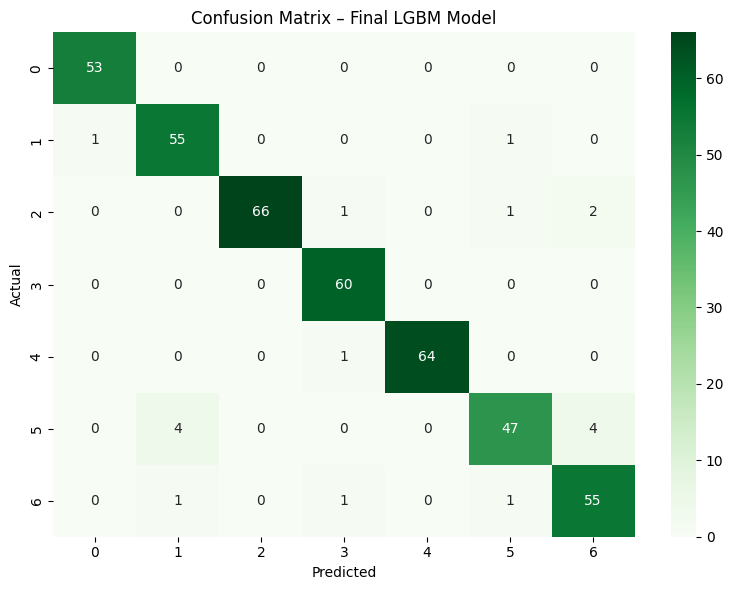

In [156]:
cm = confusion_matrix(y2_test, y2_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix – Final LGBM Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# Final Model Comparison


## Summary Table

| Model                      | Train Acc | Test Acc | CV Acc   | Overfitting | Generalization | Notes                                |
|---------------------------|-----------|----------|----------|-------------|----------------|--------------------------------------|
| **LGBM (Random Search)**  | 1.00      | ~0.95    | ~0.95    | Moderate    | Very Good      | Strong but overfits early            |
| **SVM (Random Search)**   | ~0.97     | ~0.95    | ~0.95    | Low         | Excellent       | Very stable and consistent           |
| **LGBM (Manual Tune)**    | ~0.99     | ~0.94    | N/A      | Reduced     | Good            | Adjusted depth & regularization      |
| **LGBM (Grid Search)**    | 1.00      | ~0.94    | ~0.94    | Moderate    | Good            | Thorough search, decent results      |
| **LGBM + Feature Select** | ~0.99     | ~0.93    | N/A      | Low         | Decent          | Simpler model using top features     |
| **Ensemble (LGBM + SVM)** | ~0.99     | ~0.96    | ~0.96    | Mild        | Excellent       | Best overall performance             |

---

## Cross-Validation Accuracy

| Model     | Mean CV Accuracy |
|-----------|------------------|
| **LGBM**  | ~94.4%           |
| **SVM**   | ~95.0%           |
| **Ensemble** | **96.0%**     |

---

## Final Thoughts

- **Ensemble** gave the best accuracy, blending SVM’s stability and LGBM’s power.
- **SVM** was the most reliable and generalizable.
- **LGBM** was strong but showed signs of overfitting early on smaller data.

